# Respirer a un prix : qualité de l'air et coût de la vie en Île-de-France

## Introduction 

Ce projet propose une exploration des liens entre la qualité de l'air, et plus précisément les concentrations des principaux polluants atmosphériques, et le coût de la vie en Île-de-France, entendu dans un double sens : le coût de la vie au sens littéral, mesuré par la mortalité, et le coût de la vie au sens économique, mesuré par les prix de l'immobilier. Dans un contexte de tensions climatiques et de hausse du coût de la vie, il nous semble pertinent d'analyser les liens entre ces dimensions en étudiant leurs évolutions et leurs interactions à travers les données. 

Deux raisons principales motivent l'approche de ce projet. D'une part, la qualité de l'air a un effet direct sur la santé : la population exposée présente un risque accru de maladies cardiovasculaires et respiratoires. D'autre part, la qualité de l'air fait partie de l'environnement, urbain comme rural, dans lequel vit la population, et constitue donc l'une des caractéristiques d'un lieu de vie. À ce titre, elle peut à son tour se refléter dans les prix des logements.





### Chargement des packages et Explication d'utilisation

Notre projet est structure de la façon suivante:

1) Récupération des données et premières manipulations: Dans cette section, on explique comment on obtient les données qui seront utilsées dans notre analyse et on décrit les manipulations qui seront faites pour les preparer pour l'analyse.

2) Statistiques descriptives/Visualisation: Cette section présente la distribution et les premières analyses de nos données.

3) Analyse et Résultats:

4) Conclusions:

In [ ]:
!pip install -r requirements.txt

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import s3fs
import geopandas as gpd
import io
import zipfile
import seaborn as sns
from matplotlib.colors import LogNorm
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from CODE import functions_emissions 

np.random.seed(123) 

## 1- Récupération des données et premières manipulations 

description (infos générales, NA, outliers, MaR, champs statistique (qui est couvert par mes données))

### a. Pollution

Nos données pour les emissions/polluants principaux de l'Île-de-France couvrent des effets differentes particules et gaz qui vont impacter la qualité de l'air et donc la santé de la population. Pour le choix des gaz et particules à inclure dans notre étude, on se base sur les articles déjà existants. On a tout d'abord la pollution provenant des véhicules à énergie fossile, majoritairement représentée par le Dyoxide d'Azote ($\mathrm{NO_2}$). De plus, les particules fines ($\mathrm{PM_{2.5}}$) qui ont pour source la combustion du bois, le traffic et l'industrie. C'est important de prendre en compte ces particules puisqu'elles sont fortement liées à la mortalité. Finalement, l'ozone $\mathrm{O_3}$ est aussi souvent pris en compte lors des études sur la qualité de l'air puisque ce gaz affecte la respiration et à des effet négatifs lors des pics de concentration. 

Airparif donne les cartes de series temporelles de ces polluants de formes differentes: pour le $\mathrm{NO_2}$ et $\mathrm{PM_{2.5}}$ on a les concentrations moyennes annuelles de l'année 2007 à l'année 2024, pour les particules fines $\mathrm{PM_{2.5}}$ on a le nombre de jours par année oú les concentrations dépassent les 120 microgrammes par mètre cube pendant plus de 8h. 

Cette sous-section est structurée en deux points: 1) l'extraction des données du site de Airparifs et 2) Reprendre directement les données par commune par année pour chaque polluant. Si le but est de lancer l'obtention des données, alors il faut faire le point 1), mais si le but est de faire l'analyse des données, alors on peut sauter la première partie est utiliser  les données stockées sur SSPCloud.

#### 1) Scraper les données des cartes de Airparif

1) On a besoin des concentrations de particules qui puissent nuire à la population. On utilise le NO2, PM2,5 et le O3. On note que la récupération de ses données n'est pas si directe comme on pourrait l'imaginer. En effet, le site the Airparif (qui est le site donnant les données sur la qualité de l'air de toute la région de l'île de France) ne donne que les valeurs des stations qui mesurent la qualité de l'air. Or, on a besoin d'une vision spatiale de toutes les communes et pas que de certaines stations. Alors, la récupération de ces données devient complexe. Néanmoins, Airparifs offre aussi des cartes intéractives qui donnent les niveaux de concentrations des particules. Donc, en utilisant ces cartes avec les données déjà modélisées sur toute l'Île de France, on pourrait réaliser notre étude. J'ai inspectionné le Slider donnant les cartes et j'ai trouvé d'oú je pouvais extraire les données depuis les geoservers de Airparifs. En inspectionant le slider j'ai pu retrouver la construction du lien des sites oú trouver les données. La fonction pour extraire les valeures sont dans le fichier .py.

2) Pour pouvoir utiliser les données on devra regrouper les données par communes de l'INSEE, donc on a besoin des coordonnées de centroïde de chaque commune. Pour cela on utilise la geo API de datagouv.fr, qui donne des coordonnées des communes.

L'idée est d'utiliser les coordonées des centroïdes des communes et de "scraper" la concentration des particules nuisant la qualité de l'air directement des données qui sont presentées sur la carte (qui modélisent directement la concentration des particules aux alentours des stations de mesure)

In [ ]:
# Données du Geoserver de Airparif 

url_base = "https://namek.airparif.fr/geoserver/Moyenne_annuelle/ows?service=WMS&version=1.3.0&request=GetFeatureInfo"
years = range(2007,2025)
particles = {"no2","o3","pm25"}


In [ ]:
# Données des centroïdes des communes de l'île de france

url_communes = "https://geo.api.gouv.fr/communes"
departement_idf = ["75","77","78","91","92","93","94","95"]

data_centroides = []

for dep in departement_idf:
    parametres = {"codeDepartement": dep, "type": "commune-actuelle,arrondissement-municipal","fields": "nom,code,codeDepartement,centre", "format": "json"}
    r = requests.get(url_communes, params = parametres).json()
    data_centroides += r
    
ile_de_fr_commune = pd.DataFrame({
    "INSEE_Commune" : [com["code"] for com in data_centroides],
    "INSEE_Departement" : [com["codeDepartement"] for com in data_centroides],
    "Nom_Commune" : [com["nom"] for com in data_centroides],
    "Latitude" : [com["centre"]["coordinates"][1] for com in data_centroides],
    "Longitude" : [com["centre"]["coordinates"][0] for com in data_centroides]})

ile_de_fr_commune = ile_de_fr_commune.drop(index=0).reset_index(drop=True) # la premiere ligne est Paris en general, donc on l'enleve

In [ ]:
# Scraper les données de concentration pour chaque commune dans l'île-de-France (Cela a pris approx 100 min)
data_concentration = []

for communes in range(ile_de_fr_commune.shape[0]):
    for particule in particles:
        for year in years:
            concentration = extract_values(url_base, ile_de_fr_commune["Longitude"].loc[communes], ile_de_fr_commune["Latitude"].loc[communes], particule, year)
            dict_year_particle = {"Year": year, "Particle": particule, "Commune": ile_de_fr_commune["Nom_Commune"].loc[communes], "Code_INSEE": ile_de_fr_commune["INSEE_Commune"].loc[communes], "Departement": ile_de_fr_commune["INSEE_Departement"].loc[communes],"Concentration": concentration}
            data_concentration.append(dict_year_particle)


In [ ]:
# Construction du Panel (Commune, année, Partibule_polluante) pour l'analyse
Data_Emissions = pd.DataFrame(data_concentration).pivot_table(index=["Commune", "Code_INSEE", "Departement", "Year"], columns= "Particle", values= "Concentration")

In [ ]:
# Stocker les données sur SSP Cloud

fs = s3fs.S3FileSystem(client_kwargs={"endpoint_url": "https://minio.lab.sspcloud.fr"})
MY_BUCKET = "tomasmossel"

with fs.open(f"{MY_BUCKET}/diffusion/concentrations_idf.parquet", "wb") as f:
    Data_Emissions.to_parquet(f)


#### 2) Récuperer directement les données des Emissions et première exploration du panel


In [ ]:
# Ouvrir le parquet directement de SSpCloud

fs = s3fs.S3FileSystem(client_kwargs={"endpoint_url": "https://minio.lab.sspcloud.fr"})
MY_BUCKET = "tomasmossel"

with fs.open(f"{MY_BUCKET}/diffusion/concentrations_idf.parquet", "rb") as f:
    Data_Emissions = pd.read_parquet(f)

Tout d'abord, on s'interesse à la structure des données poour voir si il y a eu des problèmes dans l'extraction des données. Ici, on peut voir qu'il y a un problème avec les données de certaines communes. Donc, on exlore quelle est la source de ce problème en regardant quelles sont les communes donnant ces valeures abérrantes. On peut voir que le problème vient que de la commune de Saint-Pathus, et que en l'enlevant de notre échantillon, on obtient des valeurs beaucoup plus raisonables. 

Les données de cette commune sont l'équivalent à des données NA puisque elles n'ont aucune validité. Pour ne pas corrompre notre analyse, on excluira cette commune. Cela est raisonable puisque c'est une petitte commune frontalière de l'île de france, et donc, l'exclusion n'aura pas de grandes conséquences sur nos résultats.

In [ ]:
Data_Emissions.describe()

/opt/python/lib/python3.13/site-packages/numpy/_core/_methods.py:49: RuntimeWarning: overflow encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)
/opt/python/lib/python3.13/site-packages/numpy/_core/_methods.py:49: RuntimeWarning: overflow encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)


Particle,no2,o3,pm25
count,23129.000000,2.312900e+04,2.312800e+04
mean,9.059044,inf,inf
std,263.460748,inf,inf
min,-9999.000000,-9.999000e+03,-9.999000e+03
25%,9.666734,7.769344e+00,8.835938e+00
50%,14.645324,1.168689e+01,1.130522e+01
75%,20.705441,1.724444e+01,1.402599e+01
max,69.558527,1.234500e+308,1.234500e+308


In [ ]:
Data_Emissions[Data_Emissions["o3"] >= 100]

Particle                                     no2             o3           pm25
Commune      Code_INSEE Departement Year                                      
Saint-Pathus 77430      77          2007 -9999.0  1.234500e+308  -9.999000e+03
                                    2008 -9999.0  1.234500e+308  -9.999000e+03
                                    2009 -9999.0  1.234500e+308  -9.999000e+03
                                    2010 -9999.0  1.234500e+308  -9.999000e+03
                                    2011 -9999.0  1.234500e+308  -9.999000e+03
                                    2012 -9999.0  1.234500e+308  -9.999000e+03
                                    2013 -9999.0  1.234500e+308  -9.999000e+03
                                    2014 -9999.0  1.234500e+308  -9.999000e+03
                                    2018 -9999.0  1.234500e+308  1.234500e+308
                                    2019 -9999.0   1.234500e+38   1.234500e+38
                                    2020 -9999.0  1.234500e+308   1.234500e+38
                                    2021 -9999.0  1.234500e+308   1.234500e+38

In [ ]:
Data_Emissions = Data_Emissions.drop("Saint-Pathus", level="Commune")
Data_Emissions.describe()

Particle,no2,o3,pm25
count,23112.000000,23112.000000,23112.000000
mean,15.987309,12.591292,11.770842
std,8.478551,6.656286,3.476377
min,2.177196,0.000000,6.062500
25%,9.673809,7.769270,8.835938
50%,14.652687,11.684671,11.306413
75%,20.713225,17.238471,14.021851
max,69.558527,39.922986,31.783500


### b. Mortalité 

Nous souhaitons lier la pollution à certains indices, comme la mortalité, pour tenter d'observer si corrélation il y a, voire aller plus loin jusqu'à étudier une causalité. 

Pour ce faire, nous récupérons des données sur le nombre de décès par commune en France sur datagouv. Nous allons extraire ces données et les restreindre à l'Île-de-France pour en faire une première analyse. Il est important de noter que la variable géographique liée au décès est le code_commune du décès : c'est à dire l'endroit où la personne est décédée. Ainsi, il n'indique peut être pas correctement le lieu où la personne vivait et était donc soumise à la pollution atmosphérique. C'est un détail à garder en tête pour la suite de notre analyse. 

Afin d'obtenir un indicateur un peu plus performant que simplement le nombre de décès (qui peut être trompeur du fait de l'hétérogénéité de la densité de la population, mais qui ne témoigne également pas de potentiels mouvements de population, d'exode rural ou bien de désertification), nous récupérons également des données sur le nombre d'habitants par commune. Ainsi, nous pourrons calculer un taux de mortalité. Nous verrons ensuite si celui-ci nous apporte une information supplémentaire. 

#### Nombre de décès

Nous commençons par télécharger les données sur le nombre de décès à partir de data.gouv.

In [4]:
url_deces = f"https://www.data.gouv.fr/api/1/datasets/r/0b0c0fbc-af9a-4b9d-9949-b171e7e6fe4a"
deces = pd.read_csv(url_deces, sep=';')
deces.head()

,code_lieu_deces,deces_2008,deces_2009,deces_2010,deces_2011,deces_2012,deces_2013,deces_2014,deces_2015,deces_2016,...,deces_2024,deces_2025,total_2008_2025,moy_annuelle,annee_pic,deces_annee_pic,evol_pct_2008_vs_2025,tendance,surplus_covid_2020,surplus_pct_covid_2020
0,31555,4559,4647,4650,4763,4924,4877,4981,5208,5153,...,5433,5626,92323,5129.1,2022,5642,23.4,Forte hausse,-9,-0.2
1,06088,4663,4576,4323,4416,4703,4763,4667,4803,4957,...,4651,4695,85661,4758.9,2021,5253,0.7,Stable,163,3.4
2,59350,4155,4224,4182,4081,4346,4499,4469,4466,4586,...,4334,4436,80527,4473.7,2020,4886,6.8,Hausse,225,4.8
3,33063,4155,4212,4178,4090,4306,4236,4379,4535,4221,...,4142,4108,76144,4230.2,2015,4535,-1.1,Stable,-124,-2.9
4,67482,3717,3743,3765,3753,3893,4188,4045,4213,4016,...,4380,4415,74441,4135.6,2020,4730,18.8,Hausse,619,15.1


In [5]:
deces.info()

<class 'pandas.DataFrame'>
RangeIndex: 36765 entries, 0 to 36764
Data columns (total 27 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   code_lieu_deces         36765 non-null  str    
 1   deces_2008              36765 non-null  int64  
 2   deces_2009              36765 non-null  int64  
 3   deces_2010              36765 non-null  int64  
 4   deces_2011              36765 non-null  int64  
 5   deces_2012              36765 non-null  int64  
 6   deces_2013              36765 non-null  int64  
 7   deces_2014              36765 non-null  int64  
 8   deces_2015              36765 non-null  int64  
 9   deces_2016              36765 non-null  int64  
 10  deces_2017              36765 non-null  int64  
 11  deces_2018              36765 non-null  int64  
 12  deces_2019              36765 non-null  int64  
 13  deces_2020              36765 non-null  int64  
 14  deces_2021              36765 non-null  int64  
 

Nous avons donc bien le code_lieu_deces, qui correspond au code_commune INSEE et est bien en caractère (donc pas de problème pour les communes commençant par 0), ainsi que le nombre de décès au sein de la commune, de l'année 2008 à 2025. Nous pouvons remarquer que les variables contenant le nombre de décès par année ne contiennent aucune valeur manquante à priori. Nous pouvons alors penser qu'une valeur manquante a été remplacée par un 0. Nous allons vérifier ensuite si certaines communes n'enregistrent aucun décès. 

Certaines statistiques descriptives sont déjà calculées, comme le total sur cette période, la moyenne annuelle, l'année pic ou bien l'évolution entre 2008 et 2025. Une certaine importance est déjà donnée au Covid et à raison : la pandémie a à la fois augmenté le nombre de décès, mais le confinement a pu réduire la pollution atmosphérique ce qui rend l'effet global sur la mortalité ambigu. 

#### Île-de-France

A présent, nous nous concentrons sur les données en Île de France. Pour cela nous allons créer une colonne département à partir de code_lieu_décès qui correspond au code de la commune. Les deux premiers chiffres sont isolés, et nous nous limitons ensuite au département d'Île-de-France. 

In [6]:
deces = deces.rename({"code_lieu_deces": "code_commune"}, axis=1)

deces["dep"] = deces["code_commune"].str[:2]
deces[["dep", "code_commune"]]
# rq : 99 fait référence aux pays étrangers : les français morts à l'étranger

,dep,code_commune
0,31,31555
1,06,06088
2,59,59350
3,33,33063
4,67,67482
...,...,...
36760,11,11094
36761,77,77356
36762,88,88117
36763,80,80035


In [7]:
deces["dep"].value_counts().sort_index()

dep
01    417
02    804
03    320
04    198
05    175
     ... 
94     47
95    183
97    136
98     82
99    198
Name: count, Length: 100, dtype: int64

Pour chaque commune, le département est bien affiché. Le nombre de commune par département semble également cohérent avec ce que nous pouvons récupérer sur internet. Pour l'Ain (01), il existe 419 communes et nous en avons 417. Pour l'Aisne, 804 pour 816, etc. 

Par ailleurs, aucune commune en Île-de-France n'a changé de département depuis 2008, donc il ne devrait pas y avoir de problème quant à cela. Nous nous limitons aux départements d'Île-de-France. 

In [8]:
dep_idf = ["75", "77", "78", "91", "92", "93", "94", "95"]
deces_idf = deces[deces["dep"].isin(dep_idf)].copy()

#nombre de communes par département 
deces_idf["dep"].value_counts().sort_index()

dep
75     20
77    513
78    262
91    193
92     36
93     41
94     47
95    183
Name: count, dtype: int64

Encore une fois le nombre de commune par département semble cohérent : nous avons les 20 arrondissements de Paris, exactement le bon nombre de commune pour le 92, 94, 95, et un nombre à quelques unités proches pour les autres. Cela peut s'expliquer par la fusion ou la séparation de commune. En effet, en se renseignant, environ 13 fusionnements de communes ont eu lieu depuis 2008. 

Dans un premier temps, nous observons la structure des données et vérifions qu'elles ne contiennent pas de doublons ou de valeurs manquantes sur toute la période (ce qui se traduirait par des zéros sur toute la ligne). 

In [9]:
print("Nombre de lignes :", len(deces_idf))
print("Nombre de communes distinctes :", deces_idf["code_commune"].nunique())
print("Doublons de code commune :", deces_idf["code_commune"].duplicated().sum())

Nombre de lignes : 1295
Nombre de communes distinctes : 1295
Doublons de code commune : 0


In [10]:
cols_deces = [f"deces_{a}" for a in range(2008, 2026)]
nb_zeros = (deces_idf[cols_deces] == 0).sum(axis=1)
print("Communes à 0 décès toutes les années :", (nb_zeros == len(cols_deces)).sum())

Communes à 0 décès toutes les années : 0


Il n'y a donc pas de doublons ou de ligne avec uniquement des décès. Ainsi, s'il existe des NA, qui ont été transformés en 0, nous ne pouvons pas les identifier avec certitude. Regardons si la part de 0 pour certaines années est incohérente

In [11]:
deces_idf["deces_2010"].value_counts().head(10)

deces_2010
0     310
1     207
2     126
3      73
4      41
5      37
6      26
7      22
9      16
17     15
Name: count, dtype: int64

In [12]:
deces_idf["deces_2015"].value_counts().head(10)

deces_2015
0     318
1     198
2     123
3      66
4      47
5      31
6      26
8      20
7      16
10     14
Name: count, dtype: int64

In [13]:
deces_idf["deces_2020"].value_counts().head(10)

deces_2020
0     299
1     203
2     106
3      63
4      53
5      30
6      23
7      19
14     16
33     13
Name: count, dtype: int64

In [14]:
deces_idf["deces_2025"].value_counts().head(10)

deces_2025
0     277
1     199
2     114
3      79
4      52
5      33
6      23
9      17
8      16
11     13
Name: count, dtype: int64

Nous remarquons que 0 est toujours une valeur assez présente, mais cela n'est pas choquant outre mesure car de nombreuses petites communes sont présentes dans la base et n'enregistrent pas forcément des décès. Si certains 0 sont des valeurs manquantes, cela ne devrait pas biaiser trop nos estimations. 


Nous pouvons à présent revenir sur la question de la fusion. Comme vu précédemment, nous avons 1295 communes (1275+20 arrondissements de Paris). Cela est globalement cohérent avec les chiffres réels : 1266 communes. Il semblerait donc il y avoir quelques communes "en trop" par rapport aux chiffres actuels. Nous pouvons émettre l'hypothèse qu'il s'agit de communes étant maintenant regroupées. 

Observons deux exemples pour voir comment se traduit ce regroupement. 
Fourqueux (78251) et Saint Germain-en-Laye (78551), tout comme Evry (91228) et Courcourronnes (91182), ont fusionné en 2019. Voyons l'évolution de la comptabilisation de leur décès. 

In [15]:
obs1 = deces_idf[(deces_idf["code_commune"] == '78551') | (deces_idf["code_commune"] == "78251")]
obs1[["code_commune", "deces_2016", "deces_2017", 'deces_2018', 'deces_2019', 'deces_2020', 'deces_2021', 'deces_2022', "deces_2023", "deces_2024", "deces_2025"]]

,code_commune,deces_2016,deces_2017,deces_2018,deces_2019,deces_2020,deces_2021,deces_2022,deces_2023,deces_2024,deces_2025
318,78551,435,441,397,417,506,242,198,179,156,174
9241,78251,9,4,5,0,0,0,0,1,0,0


In [16]:
obs2 = deces_idf[(deces_idf["code_commune"] == '91228') | (deces_idf["code_commune"] == "91182")]
obs2[["code_commune", "deces_2016", "deces_2017", 'deces_2018', 'deces_2019', 'deces_2020', 'deces_2021', 'deces_2022', "deces_2023", "deces_2024", "deces_2025"]]

,code_commune,deces_2016,deces_2017,deces_2018,deces_2019,deces_2020,deces_2021,deces_2022,deces_2023,deces_2024,deces_2025
562,91228,179,171,185,183,226,192,237,224,231,331
1197,91182,16,18,26,3,0,0,0,0,0,0


On remarque donc bien que les décès attribués à la commune ayant été 'absorbée' semblent avoir été ajoutés à la grande au moment du regroupement, sauf pour un décès en 2023 pour notre premier exemple et 3 décès en 2019 pour le deuxième. Tous les zéros semblent tout de fois indiquer que pour avoir une vision claire de l'impact des particules sur les décès géographiquement, il est pertinent de regrouper les décès des communes ayant fusionnées sur toute la période. 

In [17]:
fusions = {
    # 77
    "77166": "77316", "77170": "77316", "77299": "77316", "77491": "77316",  # Moret-Loing-et-Orvanne
    "77149": "77109",  # Chenoise-Cucharmoy
    "77028": "77433",  # Beautheil-Saints
    "77399": "77504",  # Villemaréchal
    # 78
    "78251": "78551",  # Saint-Germain-en-Laye
    "78524": "78158",  # Le Chesnay-Rocquencourt
    "78503": "78320",  # Notre-Dame-de-la-Mer
    # 91
    "91182": "91228",  # Évry-Courcouronnes
    "91222": "91390",  # Le Mérévillois
    # 93
    "93059": "93066",  # Saint-Denis
    # 95
    "95259": "95040",  # Avernes
    "95282": "95169",  # Commeny
}


df = deces_idf.copy()

df["code_commune"] = df["code_commune"].replace(fusions)

# Somme des décès par commune actuelle
deces_fus = df.groupby("code_commune", as_index=False)[cols_deces].sum()

# Variables que nous recalculons après la fusion
deces_fus["total_2008_2025"] = deces_fus[cols_deces].sum(axis=1)
deces_fus["moy_annuelle"] = deces_fus[cols_deces].mean(axis=1)
deces_fus["annee_pic"] = deces_fus[cols_deces].idxmax(axis=1).str[-4:].astype(int)
deces_fus["deces_annee_pic"] = deces_fus[cols_deces].max(axis=1)
deces_fus["dep"] = deces_fus["code_commune"].str[:2]

print(len(deces_idf), "->", len(deces_fus), "communes")

1295 -> 1281 communes


Nous obtenons maintenant un nombre plus proche du nombre actuel de communes. Il semblerait en manquer 5.

Nous avons maintenant une base de données complète, correspondant aux découpages actuels. 

#### Taux de mortalité

Le risque d'observer uniquement le nombre de mort, est que chaque commune ne compte pas le même nombre d'habitants. Ainsi, étudier l'évolution de la mortalité passe par étudier l'évolution de la démographie. 

Pour cela, nous téléchargons des données concernant le nombre d'habitants. Un des fichiers les mieux renseignés est celui sur les populations municipales (donc par communes : la différence est très minime et repose sur l'inclusion des personnes ayant plusieurs lieux de résidence). 

In [18]:
url_pop = f"https://www.data.gouv.fr/api/1/datasets/r/27361ae9-dcab-4312-97a1-48dab5f39218"
r = requests.get(url_pop)

In [19]:
z = zipfile.ZipFile(io.BytesIO(r.content))
print(z.namelist())   # les fichiers du zip

['DS_POPULATIONS_HISTORIQUES_metadata.csv', 'DS_POPULATIONS_HISTORIQUES_data.csv']


In [20]:
#le fichier que nous souhaitons avoir est celui qui ne contient pas les metadata
fichier_data_pop = [n for n in z.namelist() if "metadata" not in n][0]

#on ouvre le zip
with z.open(fichier_data_pop) as f:
    pop = pd.read_csv(f, sep=";", dtype=str)

print(pop.shape)
print(pop.columns.tolist())
pop.head()

(813234, 6)
['FREQ', 'GEO', 'GEO_OBJECT', 'POPREF_MEASURE', 'TIME_PERIOD', 'OBS_VALUE']


,FREQ,GEO,GEO_OBJECT,POPREF_MEASURE,TIME_PERIOD,OBS_VALUE
0,A,15113,COM,PMUN,2010,197
1,A,14491,COM,PMUN,2007,154
2,A,14761,COM,PMUN,2011,746
3,A,14700,COM,PMUN,2018,663
4,A,15038,COM,PMUN,2013,1040


In [21]:
pop.info()

<class 'pandas.DataFrame'>
RangeIndex: 813234 entries, 0 to 813233
Data columns (total 6 columns):
 #   Column          Non-Null Count   Dtype
---  ------          --------------   -----
 0   FREQ            813234 non-null  str  
 1   GEO             813234 non-null  str  
 2   GEO_OBJECT      813234 non-null  str  
 3   POPREF_MEASURE  813234 non-null  str  
 4   TIME_PERIOD     813234 non-null  str  
 5   OBS_VALUE       813234 non-null  str  
dtypes: str(6)
memory usage: 52.9 MB


Le nombre très élévé de lignes est du au fait que plusieurs types d'objects géographiques sont observés : les régions, les départements, les communes, les arrondissements. Nous allons conserver les geo_object étant des communes, soit COM, et ensuite se concentrer sur l'Île de France. 
Mais tout d'abord, il est possible d'observer dès les premières lignes que le tableau est dans un format particulier : en effet, une ligne correspond à une année observée. La même commune est donc présente plusieurs fois. 

Nous modifions le format du tableau afin d'obtenir une commune = une ligne. 

Pour cela, nous gardons GEO_OBJECT = COM, les communes, et une mesure par population municipale, POPREF_MEASURE = PMUN.

Après avoir effectué ce filtrage une première fois, nous avons réalisé que la commune de Paris était comptée comme une seule et unique commune. Les arrondissements sont renseignés mais sous le type ARM. Nous conservons donc aussi ARM, et au moment de la création des départements cela devrait bien nous permettre de ne garder que les arrondissements parisiens. 

In [22]:
pop["GEO_OBJECT"].value_counts()

GEO_OBJECT
COM       801734
ARR         7659
DEP         2300
ARM         1104
REG          391
FRANCE        46
Name: count, dtype: int64

In [23]:
pop_com = pop[(pop["POPREF_MEASURE"] == "PMUN") & (pop["GEO_OBJECT"].isin(["COM", "ARM"]))].copy()
pop_com

,FREQ,GEO,GEO_OBJECT,POPREF_MEASURE,TIME_PERIOD,OBS_VALUE
0,A,15113,COM,PMUN,2010,197
1,A,14491,COM,PMUN,2007,154
2,A,14761,COM,PMUN,2011,746
3,A,14700,COM,PMUN,2018,663
4,A,15038,COM,PMUN,2013,1040
...,...,...,...,...,...,...
813229,A,16193,COM,PMUN,2015,1016
813230,A,15262,COM,PMUN,2014,534
813231,A,15260,COM,PMUN,2018,110
813232,A,15021,COM,PMUN,2023,665


In [24]:
pop_com["TIME_PERIOD"] = pop_com["TIME_PERIOD"].astype(int)
pop_com["OBS_VALUE"] = pd.to_numeric(pop_com["OBS_VALUE"], errors="coerce")

# on ne garde que la période utile par rapport aux données sur la mortalité 
pop_com = pop_com[pop_com["TIME_PERIOD"] >= 2008]

#on tourne le dataframe
pop_wide = pop_com.pivot(index="GEO", columns="TIME_PERIOD", values="OBS_VALUE")
pop_wide.columns = [f"pop_{annee}" for annee in pop_wide.columns]
pop_wide = pop_wide.reset_index().rename(columns={"GEO": "code_commune"})

pop_wide.head()

,code_commune,pop_2008,pop_2009,pop_2010,pop_2011,pop_2012,pop_2013,pop_2014,pop_2015,pop_2016,pop_2017,pop_2018,pop_2019,pop_2020,pop_2021,pop_2022,pop_2023
0,01001,791,787,784,780,777,767,767,767,767,776,771,779,806,832,859,860
1,01002,194,207,221,234,235,236,239,241,243,248,253,256,262,267,273,270
2,01004,12792,13350,13835,13839,14233,14359,14022,14127,14081,14035,14204,14134,14288,14854,15554,15934
3,01005,1567,1592,1616,1600,1642,1635,1627,1619,1671,1689,1720,1751,1782,1897,1917,1906
4,01006,123,120,116,112,110,108,109,109,110,111,112,112,113,113,114,115


In [25]:
pop_wide.shape

(34906, 17)

In [26]:
pop_wide['dep'] = pop_wide['code_commune'].str[:2]
pop_idf = pop_wide[pop_wide["dep"].isin(dep_idf)].copy()
pop_idf["dep"].value_counts().sort_index()

dep
75     22
77    507
78    259
91    194
92     36
93     39
94     47
95    183
Name: count, dtype: int64

Pour Paris, il nous faut 20 arrondissements. Une valeur en trop est celle de la population totale de la ville de Paris, mais il semblerait y avoir encore une autre ligne supplémentaire. Observons. 

In [27]:
pop_test = pop_idf[pop_idf['dep']=="75"]
pop_test

,code_commune,pop_2008,pop_2009,pop_2010,pop_2011,pop_2012,pop_2013,pop_2014,pop_2015,pop_2016,pop_2017,pop_2018,pop_2019,pop_2020,pop_2021,pop_2022,pop_2023,dep
29221,75056,2211297,2234105,2243833,2249975,2240621,2229621,2220445,2206488,2190327,2187526,2175601,2165423,2145906,2133111,2113705,2103778,75
29222,75101,17440,17614,17308,17443,17100,17022,16717,16545,16252,16266,16093,15917,16030,15919,15475,15114,75
29223,75102,21793,22400,23009,22927,22390,21741,21263,20796,20260,20900,21420,21595,21130,21119,20433,19847,75
29224,75103,34824,35655,35652,36120,35991,35666,35077,35049,34788,34115,34020,34025,33402,32793,32772,32179,75
29225,75104,27977,28192,28012,27887,27769,27335,26796,27146,27487,28088,28763,29131,29064,28324,28039,27332,75
29226,75105,62143,61531,60938,60800,60179,60273,60030,59333,59108,58850,58379,58227,57380,56841,55925,55252,75
29227,75106,44322,43143,43451,43880,43224,43479,43134,42428,40916,41100,40525,40303,39625,40209,40432,40389,75
29228,75107,57082,57442,57974,57786,57092,56325,55486,54133,52512,51367,50196,48888,48520,47947,48196,48015,75
29229,75108,38702,40278,41280,40589,38749,39175,38257,36694,36453,36808,36222,35655,35631,35123,35418,35317,75
29230,75109,59157,60275,60139,60120,59474,59427,59389,59408,59629,59555,59835,60026,60168,58951,58419,57271,75


Il y a en effet le 75056 qui correspond au code de Paris, mais aussi un 751XX. Nous retirons ces deux lignes 

In [28]:
pop_fus = pop_idf[~pop_idf["code_commune"].isin(["75056", "751XX"])].copy()
pop_fus[pop_fus['dep'] == "75"]

,code_commune,pop_2008,pop_2009,pop_2010,pop_2011,pop_2012,pop_2013,pop_2014,pop_2015,pop_2016,pop_2017,pop_2018,pop_2019,pop_2020,pop_2021,pop_2022,pop_2023,dep
29222,75101,17440,17614,17308,17443,17100,17022,16717,16545,16252,16266,16093,15917,16030,15919,15475,15114,75
29223,75102,21793,22400,23009,22927,22390,21741,21263,20796,20260,20900,21420,21595,21130,21119,20433,19847,75
29224,75103,34824,35655,35652,36120,35991,35666,35077,35049,34788,34115,34020,34025,33402,32793,32772,32179,75
29225,75104,27977,28192,28012,27887,27769,27335,26796,27146,27487,28088,28763,29131,29064,28324,28039,27332,75
29226,75105,62143,61531,60938,60800,60179,60273,60030,59333,59108,58850,58379,58227,57380,56841,55925,55252,75
29227,75106,44322,43143,43451,43880,43224,43479,43134,42428,40916,41100,40525,40303,39625,40209,40432,40389,75
29228,75107,57082,57442,57974,57786,57092,56325,55486,54133,52512,51367,50196,48888,48520,47947,48196,48015,75
29229,75108,38702,40278,41280,40589,38749,39175,38257,36694,36453,36808,36222,35655,35631,35123,35418,35317,75
29230,75109,59157,60275,60139,60120,59474,59427,59389,59408,59629,59555,59835,60026,60168,58951,58419,57271,75
29231,75110,94321,95911,95394,94027,94474,92494,92228,91770,91932,90372,88557,86472,83459,83543,81926,83873,75


In [29]:
pop_fus["dep"].value_counts().sort_index()

dep
75     20
77    507
78    259
91    194
92     36
93     39
94     47
95    183
Name: count, dtype: int64

A présent, nous avons la population par commune de l'Île de France. 
Voyons si les communes correspondent avec celles liées aux décès. 

In [30]:
cols_pop = [f"pop_{a}" for a in range(2008, 2024)]

# Garder seulement les colonnes utiles, pour ne pas traîner les colonnes dérivées
d = deces_fus[["code_commune"] + cols_deces]
p = pop_fus[["code_commune"] + cols_pop]

check = d.merge(p, on="code_commune", how="outer", indicator=True)
print(check["_merge"].value_counts())

print("Seulement dans décès :", sorted(check.loc[check["_merge"] == "left_only", "code_commune"]))
print("Seulement dans pop   :", sorted(check.loc[check["_merge"] == "right_only", "code_commune"]))

_merge
both          1280
right_only       5
left_only        1
Name: count, dtype: int64
Seulement dans décès : ['93350']
Seulement dans pop   : ['77532', '91075', '91145', '91526', '95144']


Il y a ainsi 6 communes qui ne feront pas partie du dataframe commun : Vulaines-lès-Provins (77) , Bois-Herpin, Chatignonville et Roinvilliers (91), Châtenay-en-France (95). Ces communes n'ayant pas plus de 120 habitants, leur absence ne dévrait pas biaiser les résultats. Le code 93350 n'existe que dans le fichier des décès et ne contient qu'un seul décès sur la période (2010). 

Nous pouvons maintenant créer une base mergée afin de calculer le taux de mortalité. 

In [31]:
base = d.merge(p, on="code_commune", how="inner", validate="one_to_one")
print(len(base), "communes dans la base")

print("NaN décès :", base[cols_deces].isna().sum().sum())
print("NaN pop   :", base[cols_pop].isna().sum().sum())
print("Communes avec une population à 0 ou manquante :",
      ((base[cols_pop] == 0) | base[cols_pop].isna()).any(axis=1).sum())

base

1280 communes dans la base
NaN décès : 0
NaN pop   : 0
Communes avec une population à 0 ou manquante : 0


,code_commune,deces_2008,deces_2009,deces_2010,deces_2011,deces_2012,deces_2013,deces_2014,deces_2015,deces_2016,...,pop_2014,pop_2015,pop_2016,pop_2017,pop_2018,pop_2019,pop_2020,pop_2021,pop_2022,pop_2023
0,75101,39,40,44,45,33,35,27,37,40,...,16717,16545,16252,16266,16093,15917,16030,15919,15475,15114
1,75102,40,40,38,32,30,32,18,29,21,...,21263,20796,20260,20900,21420,21595,21130,21119,20433,19847
2,75103,55,49,52,52,69,46,52,58,58,...,35077,35049,34788,34115,34020,34025,33402,32793,32772,32179
3,75104,282,312,283,277,259,133,55,42,40,...,26796,27146,27487,28088,28763,29131,29064,28324,28039,27332
4,75105,544,560,603,646,680,709,675,478,366,...,60030,59333,59108,58850,58379,58227,57380,56841,55925,55252
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1275,95676,0,0,2,2,1,0,0,0,0,...,503,508,506,503,497,490,490,489,487,498
1276,95678,1,3,1,2,1,4,1,2,3,...,838,851,863,859,861,861,857,852,848,858
1277,95680,456,419,382,259,355,273,243,258,120,...,27571,27564,27247,27676,28041,28423,28636,28836,29238,30053
1278,95682,0,0,0,0,0,0,0,0,1,...,177,179,183,185,187,189,193,196,198,205


Nous calculons à partir de base le taux de mortalité de chaque ville pour chaque année que nous stockons dans un nouveau dataset appelé taux. Il s'agit ici du taux de mortalité pour 1000 habitants.

In [32]:
annees_pop = range(2008, 2024)   # la population s'arrête en 2023

taux = pd.concat([base[["code_commune"]]] + [(base[f"deces_{a}"] / base[f"pop_{a}"] * 1000).rename(f"taux_{a}") for a in annees_pop], axis=1)

taux["dep"] = taux["code_commune"].str[:2]
taux.head()

,code_commune,taux_2008,taux_2009,taux_2010,taux_2011,taux_2012,taux_2013,taux_2014,taux_2015,taux_2016,taux_2017,taux_2018,taux_2019,taux_2020,taux_2021,taux_2022,taux_2023,dep
0,75101,2.236239,2.270921,2.542177,2.579831,1.929825,2.056163,1.615122,2.236325,2.461236,2.459117,2.112720,1.570648,2.495321,2.512721,1.873990,2.778881,75
1,75102,1.835452,1.785714,1.651528,1.395734,1.339884,1.471873,0.846541,1.394499,1.036525,1.291866,1.400560,1.296596,1.183152,1.325820,1.125630,1.310022,75
2,75103,1.579371,1.374281,1.458544,1.439646,1.917146,1.289744,1.482453,1.654826,1.667242,1.260443,1.263962,1.322557,1.916053,1.890647,1.403637,1.553808,75
3,75104,10.079708,11.066969,10.102813,9.932944,9.326947,4.865557,2.052545,1.547189,1.455233,1.851324,2.051246,1.922351,1.651528,1.588759,1.640572,2.378165,75
4,75105,8.754003,9.101104,9.895303,10.625000,11.299623,11.763144,11.244378,8.056225,6.192055,5.556500,6.526319,6.199873,6.709655,5.594553,4.649084,4.814305,75


### c. Prix de l'immobilier 

Pour obtenir des données publiques sur les prix de l'immobilier en Île de France, on va utiliser le site datagouv qui met a disposition un csv contenant des prix median au m2 par commune et par année dans pas mal de communes en France.
Le seul soucis est qu'il ne couvre pas toutes les communes pour certaines raison:
- Il faut que la commune concernée possède une page sur le site Terralyze.
- Il faut qu'il y ait eu plus de 5 ventes éffectuée durant l'année.
- Il faut que le bien vendu ait une surface comprise entre 20 et 500 m2 et un prix au m2 compris entre 1000 euros et 50 000 euros pour être pris en compte.

In [3]:
url = 'https://static.data.gouv.fr/resources/prix-immobilier-par-commune-ventes-2014-a-2025-dvf-millesime-2026/20261026-112727/prix-immobilier-communes-series-2014-2025.csv'
response = requests.get(url)
if response.status_code == 200:
    with open("data_immo_price.csv", "wb") as file:
        file.write(response.content)

In [23]:
df = pd.read_csv("data_immo_price.csv")
df.head(1)

,code_insee,commune,code_departement,departement,region,population,annee,prix_m2_median,prix_m2_median_appartement,prix_m2_median_maison,prix_m2_median_neuf,ventes,ventes_maisons,ventes_appartements,source
0,01004,Ambérieu-en-Bugey,01,Ain,Auvergne-Rhône-Alpes,15934.0,2014,1840.0,1994.0,1672.0,2684.0,139,NaN,NaN,"DVF (demandes de valeurs foncières, DGFiP, Lic..."


In [24]:
print(f'Le Dataframe comporte les colonnes suivantes: {df.columns} et a pour shape: {df.shape}. En tout il comporte les données de {df['commune'].nunique()} communes.')

Le Dataframe comporte les colonnes suivantes: Index(['code_insee', 'commune', 'code_departement', 'departement', 'region',
       'population', 'annee', 'prix_m2_median', 'prix_m2_median_appartement',
       'prix_m2_median_maison', 'prix_m2_median_neuf', 'ventes',
       'ventes_maisons', 'ventes_appartements', 'source'],
      dtype='str') et a pour shape: (61327, 15). En tout il comporte les données de 5208 communes.


Nettoyons le afin de conserver un DataFrame plus propre avec une ligne par communes et une colonne par année.

In [ ]:
df = df.drop(columns = ['population', 'prix_m2_median_appartement','prix_m2_median_maison','prix_m2_median_neuf','ventes', 'ventes_maisons', 'ventes_appartements','source'])

In [30]:
#Comme le DataFrame contient une ligne par année et par commune, on le tourne pour l'indexer sur les communes et mettre les années en colonnes.
P1 = df.pivot(
    index = 'code_insee',
    columns = 'annee',
    values = 'prix_m2_median'
)
P1.head()
#On reconstruit aussi les colonnes concernant la region et le nom de la commune
P2 = df[['code_insee', 'commune', 'region']].drop_duplicates(subset = 'code_insee')
#On merge les deux dataframe intermédiaire
Prix_immo = P2.merge(
    P1,
    left_on = 'code_insee',
    right_on = 'code_insee',
    how = 'right'
)

In [31]:
Prix_immo.head()

,code_insee,commune,region,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,01004,Ambérieu-en-Bugey,Auvergne-Rhône-Alpes,1840.0,1824.0,NaN,NaN,1855.0,2068.0,1975.0,2189.0,2419.0,2322.0,2276.0,2485.0
1,01007,Ambronay,Auvergne-Rhône-Alpes,1705.0,1439.0,1990.0,1798.0,1862.0,1786.0,1644.0,2419.0,2463.0,2595.0,2510.0,2146.0
2,01014,Arbent,Auvergne-Rhône-Alpes,1825.0,1685.0,1832.0,1133.0,1700.0,1385.0,1257.0,1910.0,2107.0,1817.0,1935.0,2046.0
3,01024,Attignat,Auvergne-Rhône-Alpes,1751.0,1569.0,1705.0,1777.0,1830.0,1857.0,1911.0,2171.0,2315.0,2275.0,2400.0,2045.0
4,01025,Bâgé-Dommartin,Auvergne-Rhône-Alpes,1644.0,NaN,1742.0,1747.0,1775.0,1837.0,1886.0,2112.0,2323.0,2260.0,1981.0,2471.0


## 2- Statistiques descriptives/Visualisation

### a. Pollution

In [ ]:
url = ("https://geo.api.gouv.fr/communes?codeRegion=11&type=commune-actuelle,arrondissement-municipal&format=geojson&geometry=contour&fields=code,nom")

communes_geo_distrib = gpd.read_file(url)
communes = communes_geo_distrib[communes_geo_distrib["code"] != "75056"]  # On enlève la commune de Paris (on prend les arrondissement)


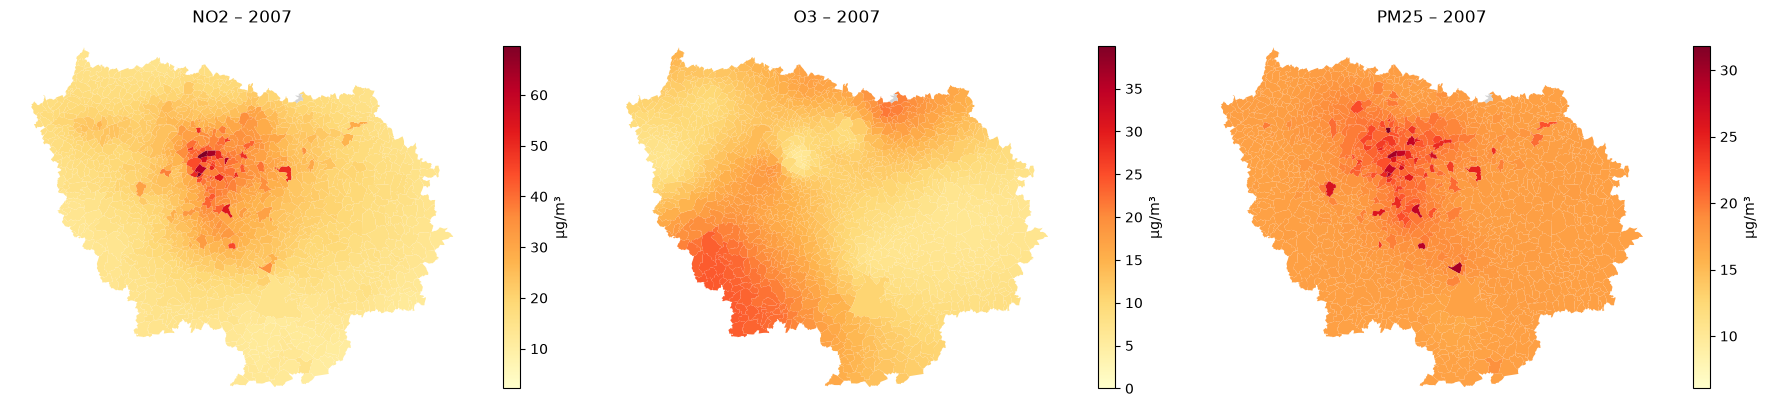

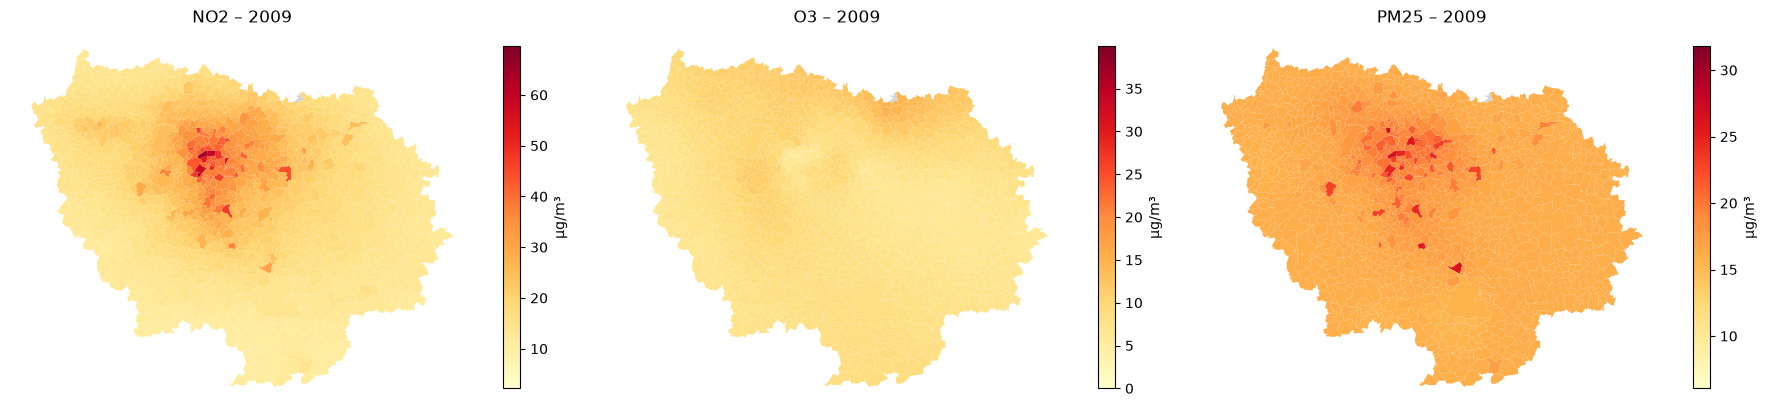

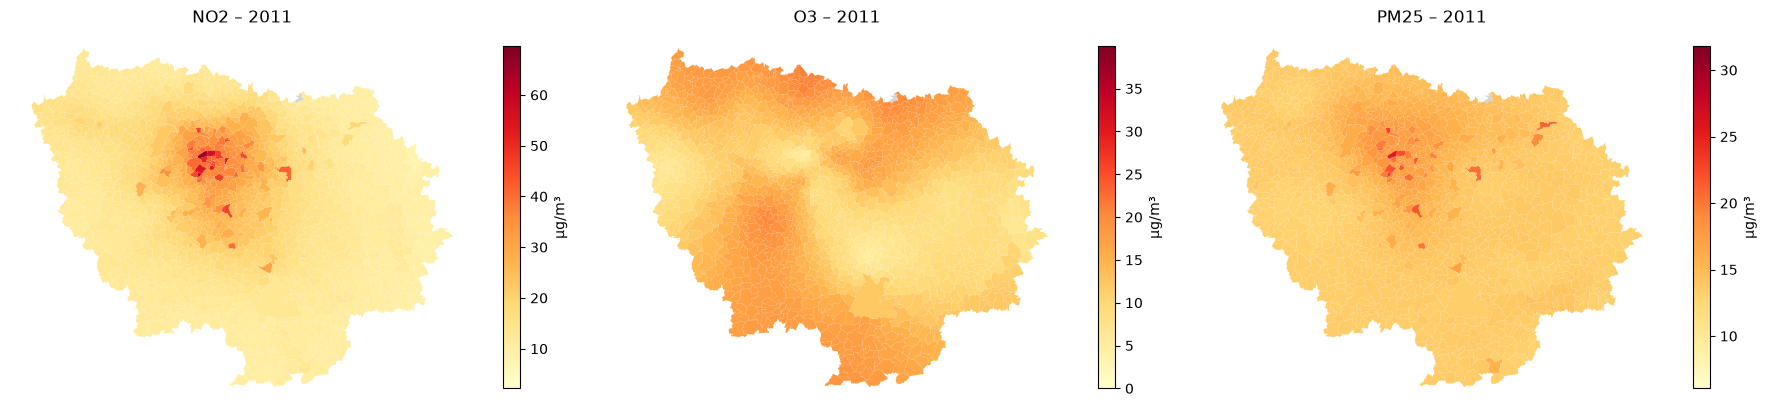

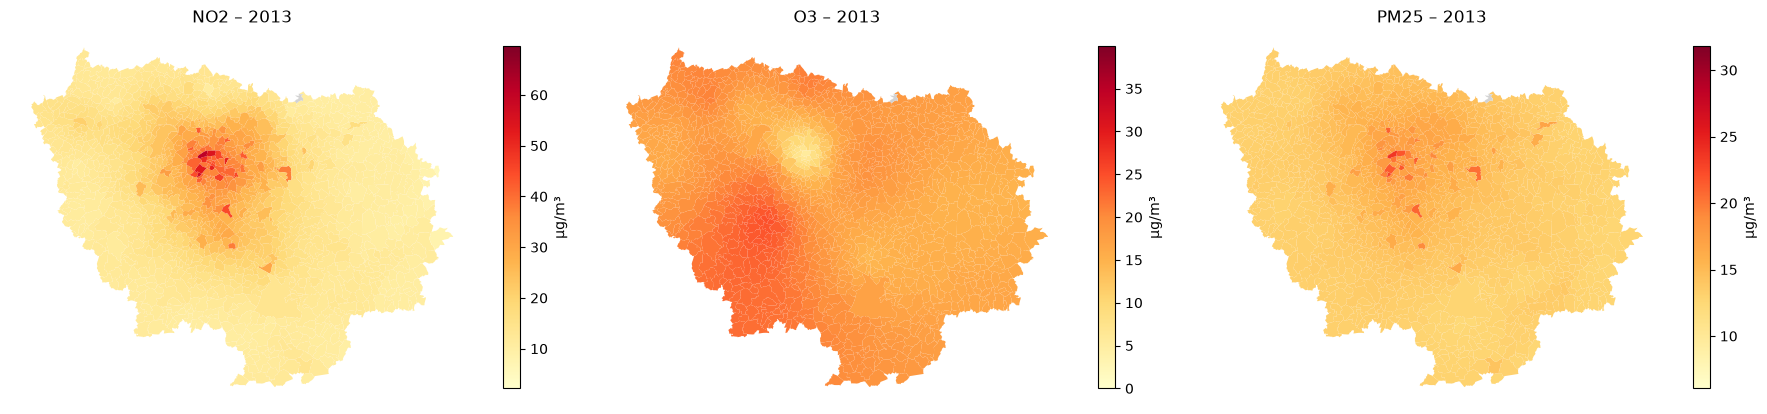

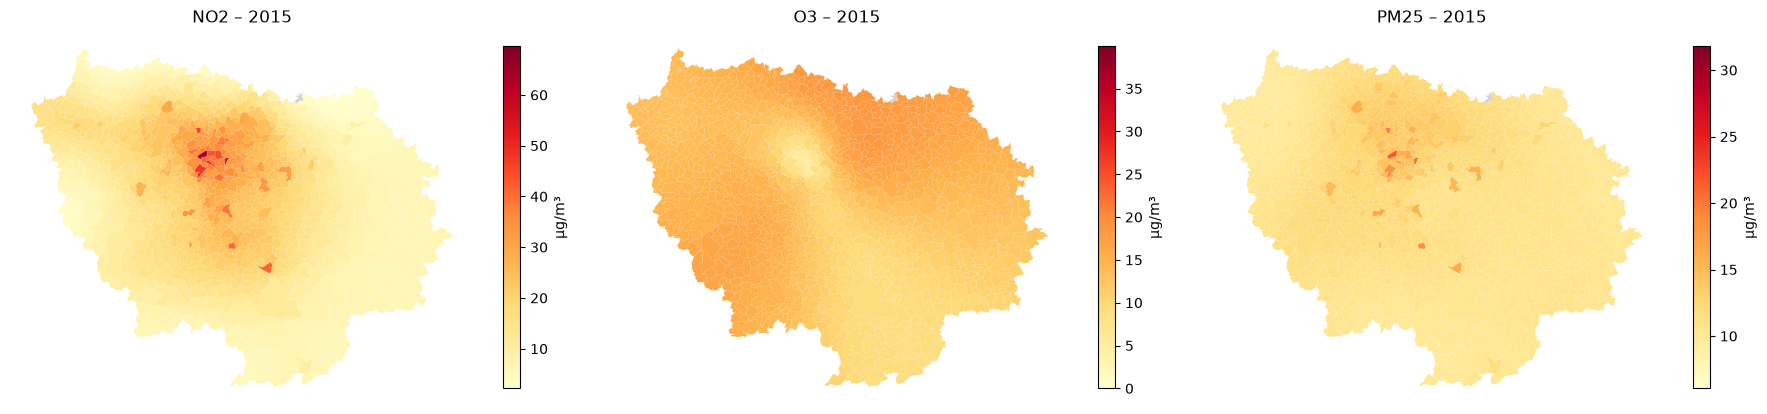

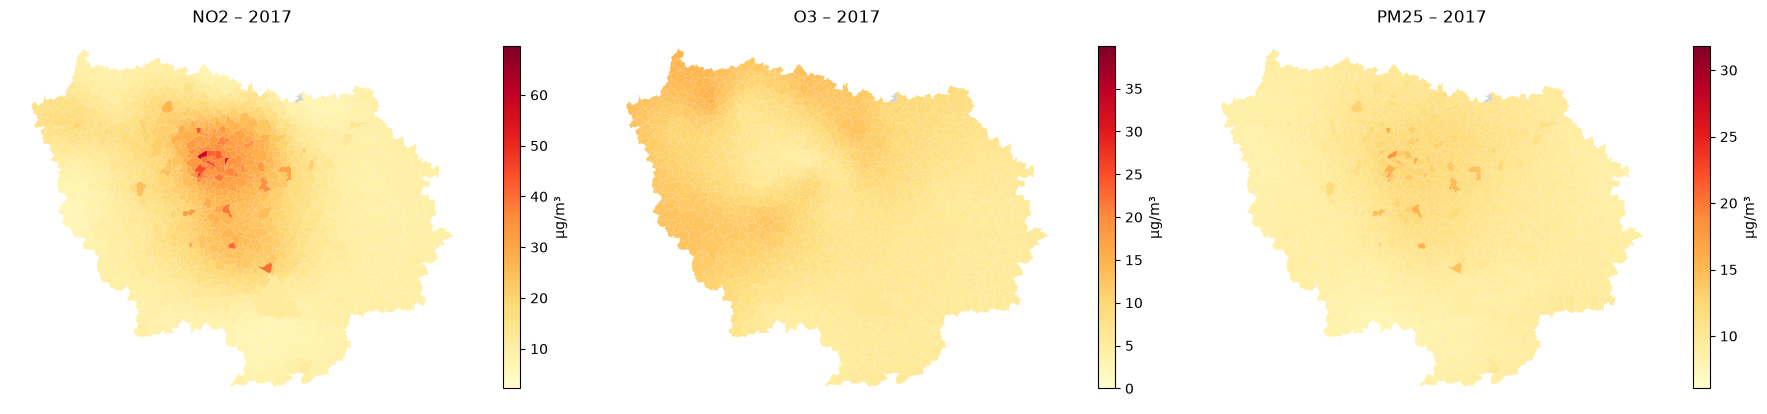

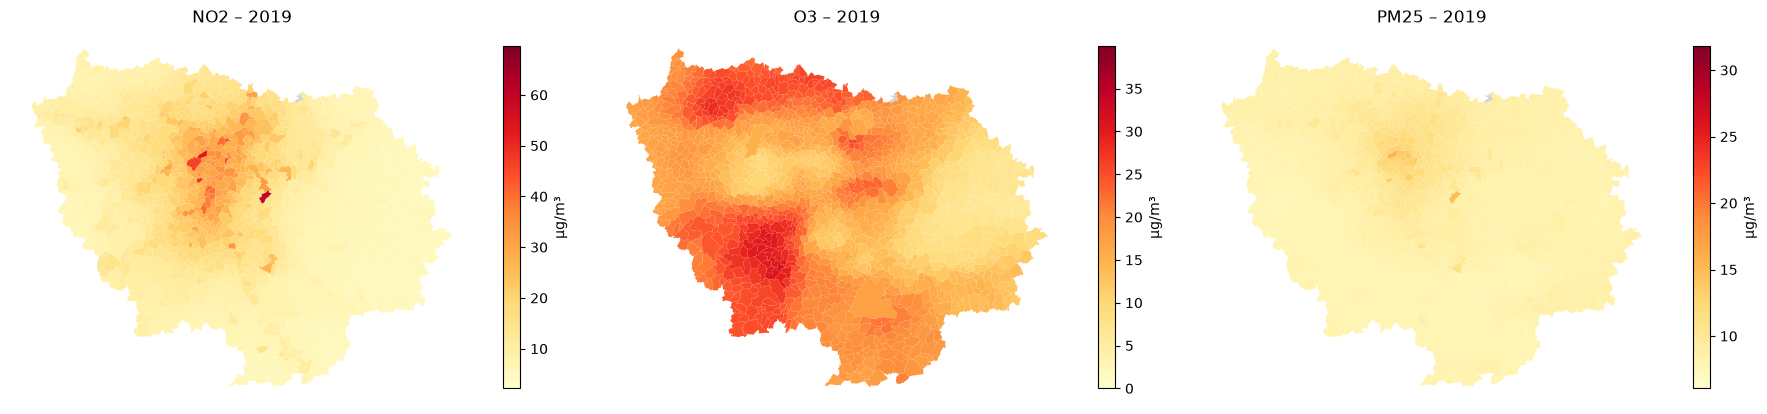

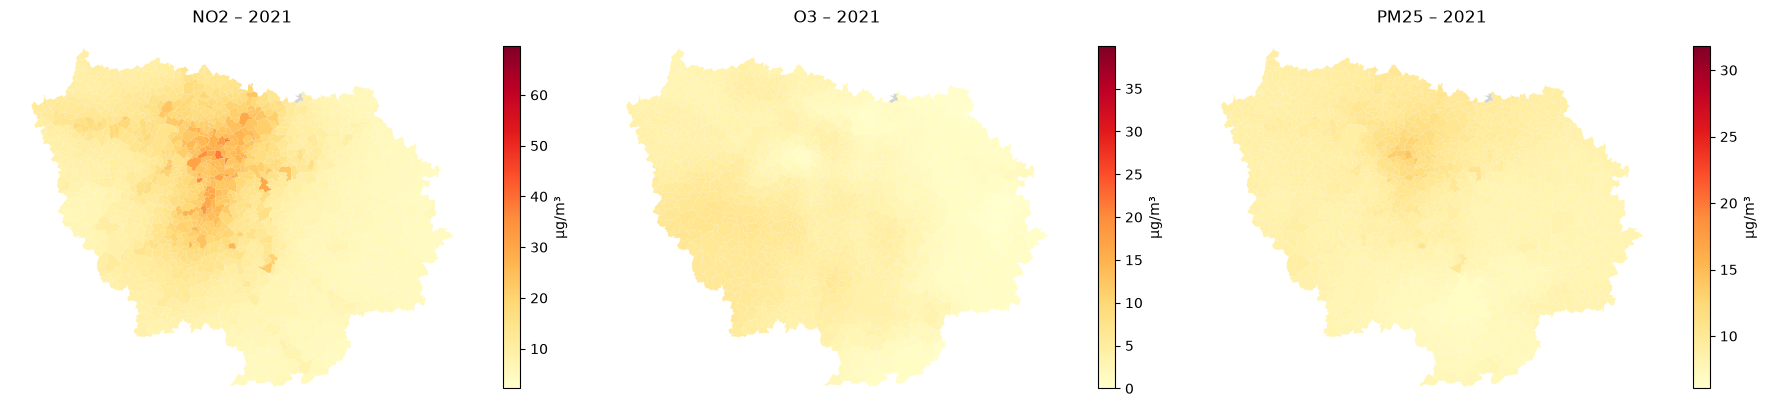

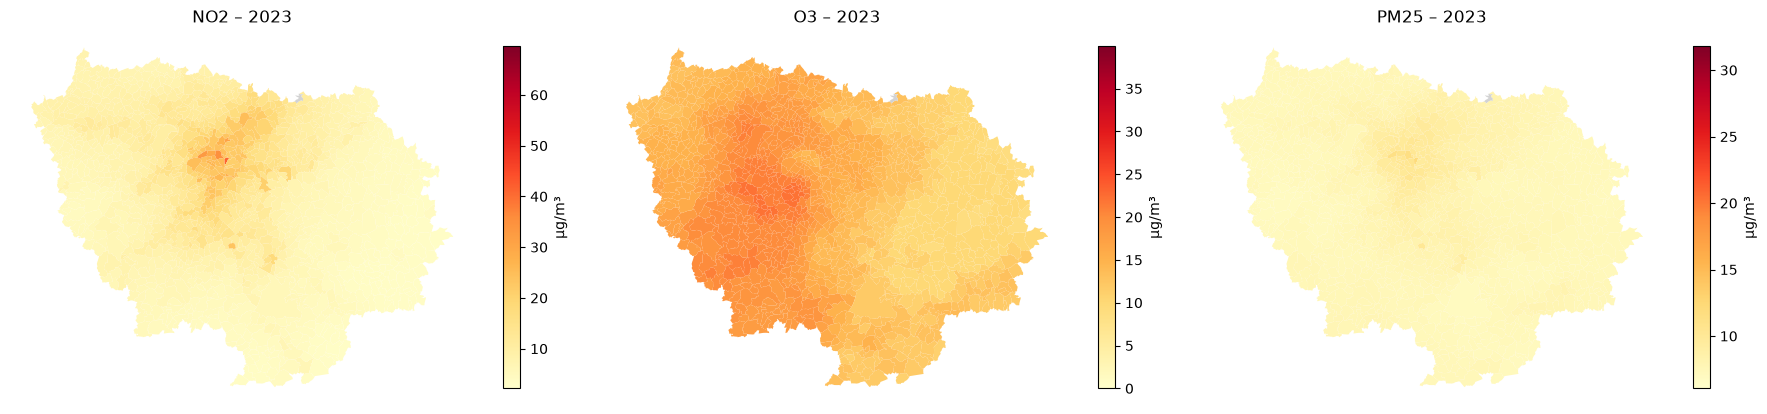

In [ ]:
avg = Data_Emissions.groupby(level=["Code_INSEE","Year"]).mean().reset_index(level="Year")
avg.index = avg.index.astype(str)   
avg.columns.name = None

particles = ["no2", "o3", "pm25"]
lims = {p: (avg[p].min(), avg[p].max()) for p in particles}

for year in range(2007,2024, 2):

    year_data = avg[avg["Year"] == year].drop(columns="Year")
    gdf = communes.merge(year_data, left_on="code", right_index=True, how="left")

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    for ax, p in zip(axes, ["no2", "o3", "pm25"]):
        vmin,vmax = lims[p]
        gdf.plot(column=p, cmap="YlOrRd", ax=ax,vmin=vmin, vmax=vmax, legend=True,
                legend_kwds={"label": "µg/m³", "shrink": 0.6},
                missing_kwds={"color": "lightgrey"})
        ax.set_title(f"{p.upper()} – {year}")
        ax.set_axis_off()
    plt.tight_layout()
    plt.show()

À première vue, on observe que les communes présentant les concentrations les plus élevées sont les communes de la zone métropolitaine parisienne pour le $\mathrm{NO_2}$ et $\mathrm{PM_{2.5}}$, tandis que pour le $\mathrm{O_3}$ c'est le contraire. De plus, on voit qu'en général, les concentrations diminuent au cours du temps pour chacun des polluants avec une baisse plus régulière pour le $\mathrm{NO_2}$ et $\mathrm{PM_{2.5}}$ que pour le $\mathrm{O_3}$ qui n'a pas une évolution monotone. Pour pouvoir interpréter cela, il faut aller regarder la composition de chacune des particules et des gaz, et leurs origines. 

En effet, le $\mathrm{NO_2}$ est majoritairement produit par les véhicules utilisant des énergies fossiles, ce qui est en ligne avec le fait que les zones parisiennes soient les plus exposées à ces gaz (aussi, on peut voir une concentration plus forte vers les grands axes routiers (periférique, grandes routes)). Par ailleurs, avec les régulations européennes, l'augmentation des véhicules éléctriques et l'implantation des zones à faibles émissions, les concentrations ont diminué substantiellement. De plus, on qu'il y a des communes éloignées du centre de Paris qui ont des niveaux élevés de $\mathrm{NO_2}$ et $\mathrm{PM_{2.5}}$. Cela pourrait être du à leur proximité aux autoroutes oú axes routiers.

De même, les particules $\mathrm{PM_{2.5}}$, on observe une diminuiton importante au cours du temps avec des faibles concentrations vers la fin de notre échantillon. 

Concernant l'ozone $\mathrm{O_3}$, on peut voir que les zones plus affectées ne sont pas les mêmes que pour les deux autres polluants. Ici, la zone de la ville de Paris semble être moins affectée que le sud-ouest de l'île de france. Cela est du au fait que le $\mathrm{O_3}$ rentre en réaction avec le monoxyde d'azote et donne du $\mathrm{NO_2}$ et de $\mathrm{O_2}$. Cela fait que sa concentration soit plus faible, et que la concentration de $\mathrm{NO_2}$ soit plus élevée.

In [ ]:
Data_Emissions_Dep = Data_Emissions.groupby(level=["Departement", "Commune"]).mean()
Data_Emissions_Dep.sort_values(["no2"], ascending=[False]).head(20)

Particle                                    no2         o3       pm25
Departement Commune                                                  
75          Paris 17e Arrondissement  54.291252   8.007388  19.665722
93          Bagnolet                  48.917384  10.800366  17.702122
92          Vanves                    45.658135  11.176984  18.045124
75          Paris 18e Arrondissement  44.778368   7.993972  17.376227
            Paris 19e Arrondissement  42.461683   9.298421  16.395474
            Paris 15e Arrondissement  41.980013   9.817961  17.105485
93          Le Bourget                40.257379  11.570482  16.340862
75          Paris 8e Arrondissement   40.060885   8.264198  16.066167
            Paris 5e Arrondissement   39.097340   9.807988  16.538740
94          Ivry-sur-Seine            38.882709  11.300061  16.118008
75          Paris 4e Arrondissement   38.865631   9.451209  15.678113
            Paris 1er Arrondissement  38.373920   8.923195  15.487008
95          Saint-Gratien             37.882755  12.048539  18.136278
92          Châtillon                 37.391320  12.185790  15.565728
75          Paris 3e Arrondissement   36.762879   9.149517  15.087750
94          Joinville-le-Pont         36.719897  11.694273  15.044209
91          Vigneux-sur-Seine         36.554014  11.871451  16.732179
            Villabé                   36.388539  11.844513  17.026950
93          La Courneuve              36.121331  11.093727  16.466403
75          Paris 16e Arrondissement  36.050111   9.184009  14.504686

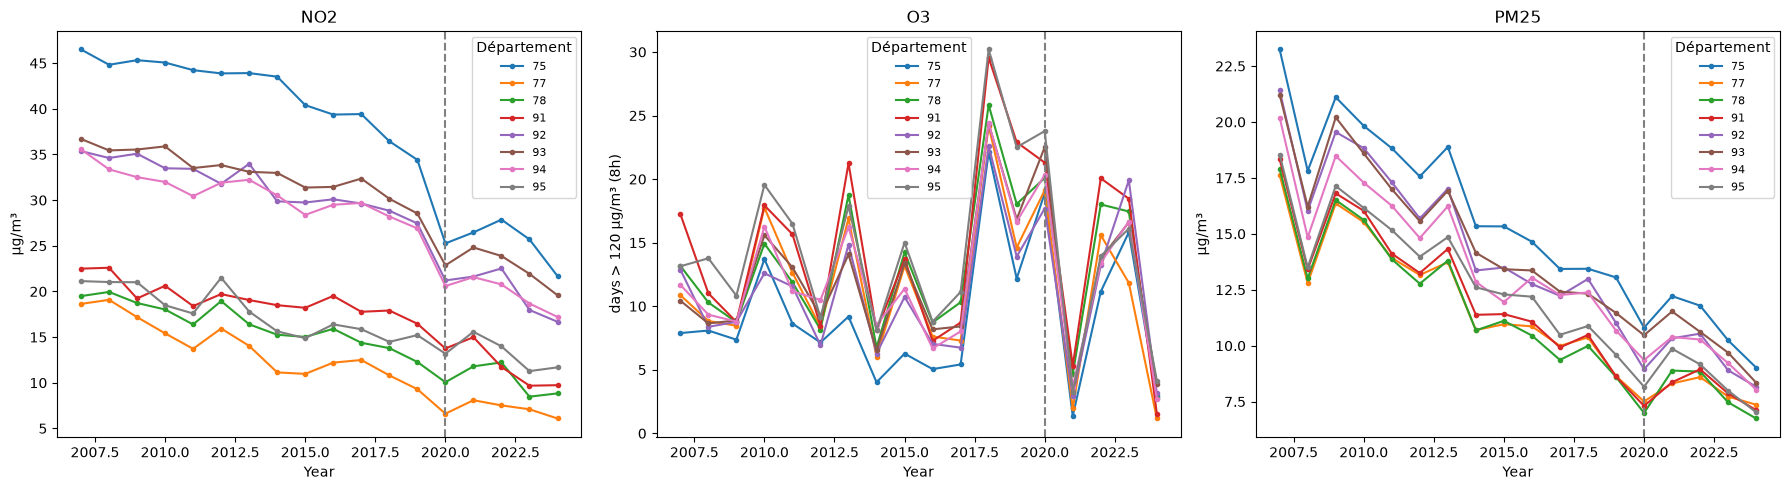

In [ ]:
# Séries Temporelles des concentrations par département

Data_Emissions_temp = Data_Emissions.groupby(level = ["Departement", "Year"]).mean()

units = {"no2": "µg/m³", "o3": "days > 120 µg/m³ (8h)", "pm25": "µg/m³"}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, p in zip(axes, ["no2", "o3", "pm25"]):
    Data_Emissions_temp[p].unstack("Departement").plot(ax=ax, marker="o", ms=3)
    ax.axvline(2020, color= "grey", linestyle="--")
    ax.set_title(p.upper())
    ax.set_xlabel("Year")
    ax.set_ylabel(units[p])
    ax.legend(title="Département", fontsize=8)
plt.tight_layout()
plt.show()



C'est interessant de regarder les séries tempoerlles pour observer les tendances de chacun des polluants. En particulier, on peut observer que le COVID 19 a eu un impact substantiel sur les concentrations de $\mathrm{NO_3}$ et $\mathrm{PM_{2.5}}$. Cela est raisonable puisque le confinement restraint les déplacements et donc réduit les emissions de ces gaz. De plus, on peut voir que l'effet est plus important dans Paris, ce qui est normal puisque c'est le centre économique de la région et donc acceuille la majorité des déplacements. 

Pour l'ozone, on observe une évolution très différente. En effet, cela est du par la forte correlation entre la concentration de $\mathrm{O_3}$ et la chaleur. On peut observer des pics de jours de haute concentration de $\mathrm{O_3}$ en 2018, 2019, 2020, et 2022, qui sont dans la liste des années avec les été les plus chaloureux depuis 1950. Donc, cette variation est expliquée par ce phénomène. Pour notre projet, ce sera important de tenir en compte ce lien puisque la mortalité sera surement correlée avec ces années de hautes chaleures.

### b. Mortalité 

#### Nombre de décès

Observons à présent des statistiques descriptives sur nos données. 

Commençons par observer comment se distribue la moyenne annuelle de décès sur la période pour chaque commune.  

In [33]:
stats = deces_fus["moy_annuelle"].describe(percentiles=[.1, .25, .5, .75, .9, .99])
print(stats.round(2))

moyenne = deces_fus["moy_annuelle"].mean()
mediane = deces_fus["moy_annuelle"].median()
print(f"\nMoyenne : {moyenne:.1f} | Médiane : {mediane:.1f} | Ratio moyenne/médiane : {moyenne/mediane:.1f}")

count    1281.00
mean       60.09
std       211.70
min         0.06
10%         0.39
25%         0.83
50%         2.67
75%        23.78
90%       120.67
99%       989.14
max      3438.39
Name: moy_annuelle, dtype: float64

Moyenne : 60.1 | Médiane : 2.7 | Ratio moyenne/médiane : 22.5


On observe un écart très important entre la moyenne et la médiane : il semblerait que la moyenne soit donc tirée très fortement vers le haut par les communes avec un très grand nombre de décès (très probablement les communes les plus peuplées). Une petite ville compte également autant qu'un arrondissement de Paris dans ces statistiques, ce qui peut expliquer l'écart très important. 

Une médiane de presque 3 décès peut tout de même paraître surprenant : c'est sûrement ici que la mention de la limite du code_deces intervient. Les petites villes n'ont probablement pas d'hôpital ou d'EHPAD, ce qui conduit les individus à se rapatrier sur d'autres communes. Ainsi, l'effet estimé est probablement déformé. Il est tout de même cohérent de penser que les individus mourant rejoignent des établissements proches de leur lieu de domicile : la comparaison que nous pourrons effectuer avec la pollution sera donc pertinente à une échelle un peu différente de celle de la commune : potentiellement un cadrage autour des pôles de santé majeurs, ou bien des départements

Voyons quelles sont les 15 communes qui concentrent le plus de décès afin de voir si notre hypothèse se confirme.

In [34]:
deces_fus.sort_values(by="moy_annuelle").tail(15)[['code_commune', 'dep', 'moy_annuelle']]

,code_commune,dep,moy_annuelle
15,75116,75,977.833333
1235,95500,95,988.833333
18,75119,75,990.388889
1042,93066,93,1025.388889
985,92023,92,1055.500000
1104,95018,95,1162.833333
19,75120,75,1189.555556
9,75110,75,1365.055556
1093,94076,94,1368.611111
17,75118,75,1517.000000


On remarque que les communes avec le plus grand nombre de décès sont majoritairement les arrondissements de Paris, ce qui est très cohérent, ainsi que certaines communes du Val-de-Marne et du Val-d'Oise. Ce sont donc sûrement celles qui sont à la fois les plus peuplées, et qui possèdent des établissements de santé. 

Voyons la commune avec la moyenne de décès la plus haute pour chaque département. 

In [35]:
maxm = deces_fus.groupby("dep")["moy_annuelle"].idxmax()
top = deces_fus.loc[maxm, ["dep", "code_commune", "moy_annuelle"]]
top

,dep,code_commune,moy_annuelle
14,75,75115,3438.388889
295,77,77288,879.500000
581,78,78158,859.666667
833,91,91174,790.333333
985,92,92023,1055.500000
1042,93,93066,1025.388889
1064,94,94028,1914.388889
1104,95,95018,1162.833333


Nous obtenons donc que les villes avec le plus de décès sont : Paris (15e), Melun (77), Le Chesnay-Rocquencourt (78), Corbeil-Essonnes (91), Clamart(92), Saint-Denis (93), Créteil (94) et Argenteuil (95). 

Nous remarquons que ces résultats sont cohérents avec nos hypothèses précédentes sur le biais induit par code_décès. Pour le 78, Versailles est une ville beaucoup plus grande que Le Chesnay, mais l’hôpital André-Mignot est dans cette dernière. Pour Paris, le 15ème est aussi connu pour être un arrondissement composé de grands hôpitaux et EHPAD. Melun n'est également pas la plus grande ville du 77, mais celle qui concentre des pôles hospitaliers majeurs. 

Le biais lié au fait que la variable code_décès indique la commune de mort et pas de résidence du défunt est donc bien visible. 

Observons à présent si le Covid a eu un impact sur la mortalité, en nous concentrant sur la variable annee_pic, qui indique pour chaque ville l'année ayant connu la plus forte mortalité 

In [ ]:
deces_fus["annee_pic"].value_counts().sort_index()

annee_pic
2008    102
2009     73
2010     65
2011     55
2012     60
2013     54
2014     35
2015     51
2016     33
2017     43
2018     41
2019     42
2020    201
2021     87
2022    101
2023     68
2024     89
2025     81
Name: count, dtype: int64

L'année étant celle avec le plus de pic de mortalité pour les communes est en effet 2020. C'est donc un autre élément à garder en tête lors de notre analyse. 

Représentons l'évolution par année de la mortalité selon les départements pour voir concrètement l'impact du Covid. 

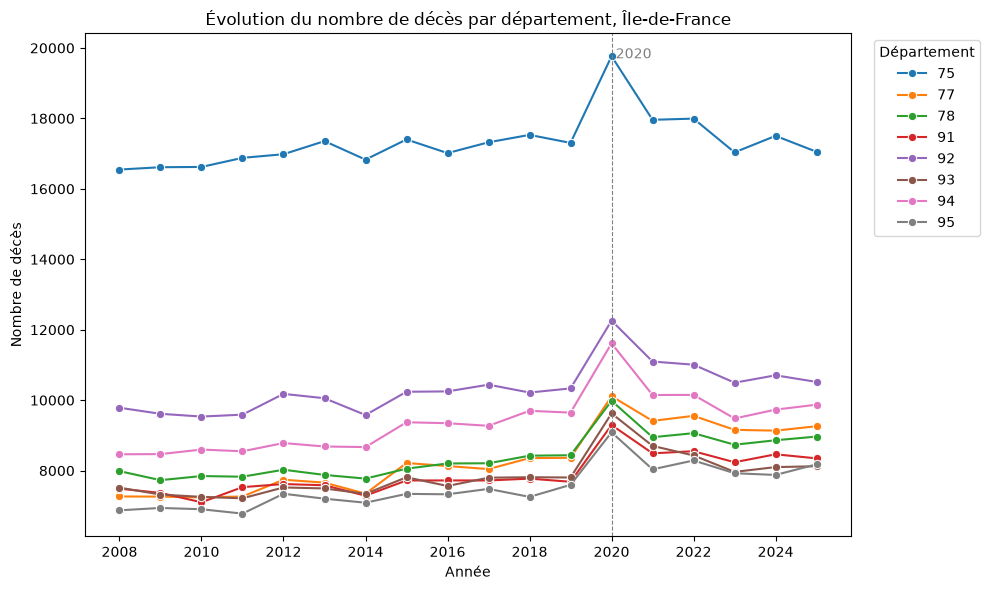

In [ ]:
ordre = ["75", "77", "78", "91", "92", "93", "94", "95"]

# Total des décès par département et par année
par_dep = deces_fus.groupby("dep")[cols_deces].sum().loc[ordre]
par_dep.columns = [int(c[-4:]) for c in par_dep.columns] #renommer les années 

# Aide de Claude pour réaliser le graphique. 
# Format long pour seaborn
long = (par_dep.reset_index()
        .melt(id_vars="dep", var_name="annee", value_name="deces"))

fig, ax = plt.subplots(figsize=(10, 6))
sns.lineplot(data=long, x="annee", y="deces", hue="dep", hue_order=ordre,
             palette="tab10", marker="o", ax=ax)
ax.axvline(2020, color="grey", linestyle="--", linewidth=0.8)
ax.text(2020.1, ax.get_ylim()[1] * 0.98, "2020", color="grey", va="top")
ax.set_xlabel("Année")
ax.set_ylabel("Nombre de décès")
ax.set_title("Évolution du nombre de décès par département, Île-de-France")
ax.set_xticks(range(2008, 2026, 2))
ax.legend(title="Département", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

Nous observons bien plusieurs éléments mentionnés précédemment : 
- l'effet population : certains départements sont beaucoup plus peuplés et ont donc plus de morts 
- l'effet Covid : 2020 est une année de pic pour chaque département 

De plus, une certaine stabilité du nombre de décès se constate également. Des évolutions différentes peuvent toutefois exister au sein même d'un département. Représentons sur une carte l'évolution du nombre de décès afin d'observer si certains chocs majeurs existent. 

Comme nous l'avons évoqué à de nombreuses reprises, les biais liés à la répartition des décès entre communes rendent difficiles la comparaison visuelle sur une même carte en prenant une échelle linéaire. Nous passons donc en log le nombre de décès afin de mieux distinguer les communes (petites et grandes) entre elles. Les zones grises correspondent donc aux communes avec aucun décès (sinon le log ne marche pas). Par ailleurs, les écarts sont un peu plus subtils à voir car ils correspondent maintenant à une multiplication. 

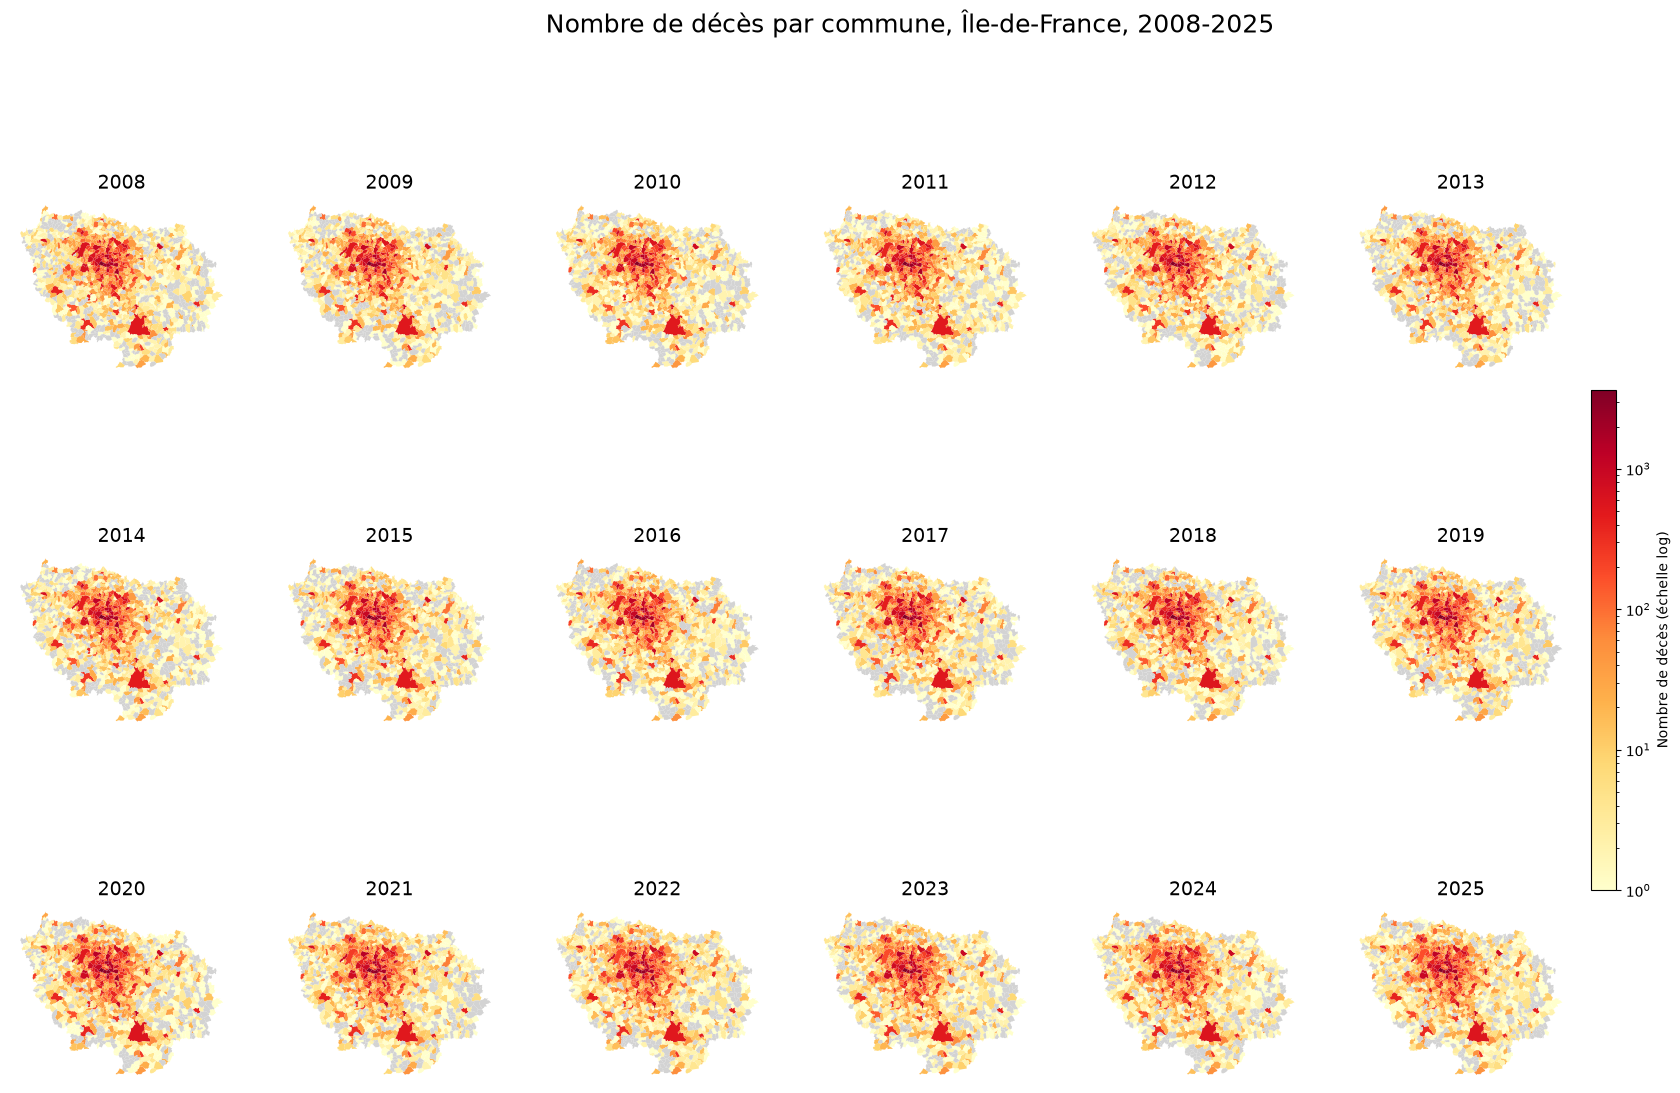

In [ ]:
url = ("https://geo.api.gouv.fr/communes?codeRegion=11"
       "&type=commune-actuelle,arrondissement-municipal"
       "&format=geojson&geometry=contour&fields=code,nom")
communes = gpd.read_file(url)
communes = communes[communes["code"] != "75056"].copy()   # on garde les arrondissements de Paris

d_map = deces_fus.set_index("code_commune")
annees_deces = range(2008, 2026)
cols = [f"deces_{a}" for a in annees_deces]
communes["geometry"] = communes.simplify(0.0003)   # ~30 m, invisible à cette échelle

cols = [f"deces_{a}" for a in annees_deces]
norm = LogNorm(vmin=1, vmax=d_map[cols].max().max())
cmap = "YlOrRd"

fig, axes = plt.subplots(3, 6, figsize=(24, 13))

for ax, a in zip(axes.flat, annees_deces):
    serie = d_map[f"deces_{a}"].where(lambda s: s > 0)
    gdf = communes.merge(serie.rename("deces"), left_on="code", right_index=True, how="left")
    gdf.plot(column="deces", cmap=cmap, norm=norm, ax=ax,
             missing_kwds={"color": "lightgrey"})
    ax.set_title(str(a), fontsize=14)
    ax.set_axis_off()

# une légende
sm = ScalarMappable(norm=norm, cmap=cmap)
cbar = fig.colorbar(sm, ax=axes, shrink=0.5, location="right", pad=0.01)
cbar.set_label("Nombre de décès (échelle log)")

fig.suptitle("Nombre de décès par commune, Île-de-France, 2008-2025", fontsize=18)
plt.show()

Nous remarquons que les décès sont concentrés sur les zones les plus peuplées. 
De gros changements de mortalité ne se constatent également pas sur ces cartes avec l'échelle en log. 

#### Taux de mortalité

Afin de réaliser quelques statistiques descriptives sur ces taux, nous calculons le taux moyen en additionnant les décès et la population pour chaque ville. Ce taux moyen est un taux PAR VILLE. En faire la moyenne donne donc la moyenne des taux mais pas un taux en Île de France.

In [36]:
# nous recréons ces variables car les années ont changé
cols_d = [f"deces_{a}" for a in annees_pop]
cols_p = [f"pop_{a}" for a in annees_pop]

taux["taux_moyen"] = base[cols_d].sum(axis=1) / base[cols_p].sum(axis=1) * 1000

In [37]:
taux["taux_moyen"].describe()

count    1280.000000
mean        4.868478
std        26.411777
min         0.000000
25%         1.285001
50%         1.782171
75%         2.930144
max       852.441715
Name: taux_moyen, dtype: float64

Nous remarquons que la moyenne des taux moyens de chaque ville entre 2008 et 2023 est de 4,86, avec une médiane de 1,78. La proportion de petites villes étant importante, la moyenne est plus élevée que la médiane : les petites villes où peu de décès sont enregistrés sont nombreuses mais la moyenne est biaisée par les villes avec un très grand taux. 

On remarque par ailleurs que certaines communes ont un taux minimum de 0, il peut s'agir des petites communes n'ayant aucun pôle de santé, tandis que d'autres peuvent avoir des taux totalement aberrants, comme 850 : sûrement les gros centres hospitaliers. 

Voyons cela de plus près. 

Commençons par regarder quelles sont les villes avec un taux presque nul.

In [38]:
taux.sort_values("taux_moyen", ascending=False).tail(10)[["code_commune", "taux_moyen"]]

,code_commune,taux_moyen
721,78505,0.303628
948,91602,0.295814
884,91374,0.277855
319,77313,0.263505
857,91247,0.249035
844,91204,0.242503
493,77498,0.215332
916,91495,0.195695
757,78606,0.000000
213,77205,0.000000


In [39]:
obs3 = deces_idf[(deces_idf["code_commune"] == '77205') | (deces_idf["code_commune"] == '78606')]
obs3[["code_commune", "deces_2016", "deces_2017", 'deces_2018', 'deces_2019', 'deces_2020', 'deces_2021', 'deces_2022', "deces_2023", "deces_2024", "deces_2025"]]

,code_commune,deces_2016,deces_2017,deces_2018,deces_2019,deces_2020,deces_2021,deces_2022,deces_2023,deces_2024,deces_2025
36271,77205,0,0,0,0,0,0,0,0,1,0
36446,78606,0,0,0,0,0,0,0,0,1,0


Gesvres-le-Chapitre (145 habitants en 2026) et Tartre-Gaudran (73 habitants en 2023) sont les deux communes avec le taux le plus faible : elles ont respectivement un seul décès enregistré sur la période. C'est encore une fois lié à ce que nous mentionnons plus tôt. 

Enfin, pour les taux les plus élevés :

In [40]:
taux.sort_values("taux_moyen", ascending=False).head(10)[["code_commune", "taux_moyen"]]

,code_commune,taux_moyen
244,77237,852.441715
189,77180,271.943574
855,91243,190.322093
826,91135,102.131400
605,78227,87.144228
486,77489,76.633892
795,91044,61.080080
720,78502,58.398128
640,78310,56.539920
627,78281,46.350292


La première ville est Jossigny, qui héberge le Grand Hôpital de l'Est Francilien. Cela semble donc cohérent avec notre hypothèse. Après vérification, les 10 communes présentes ici ont toutes au moins un établissement spécialisé, privé ou de proximité, sauf 4 : Fontenay-lès-Briis (91243), Évecquemont (78227), Vaux-sur-Lunain (77489) et Goussonville (78281), qui sont de petits villages. 

Voyons les décès associés : 

In [44]:
obs5 = deces_idf[(deces_idf["code_commune"] == '91243') | (deces_idf["code_commune"] == '78227') | (deces_idf["code_commune"] == '77489') | (deces_idf["code_commune"] == '78281')]
obs5

,code_commune,deces_2008,deces_2009,deces_2010,deces_2011,deces_2012,deces_2013,deces_2014,deces_2015,deces_2016,...,deces_2025,total_2008_2025,moy_annuelle,annee_pic,deces_annee_pic,evol_pct_2008_vs_2025,tendance,surplus_covid_2020,surplus_pct_covid_2020,dep
329,91243,446,447,446,421,387,453,349,444,398,...,99,6585,365.8,2013,453,-77.8,Forte baisse,-13,-3.2,91
1217,78227,107,89,68,81,82,81,60,62,62,...,41,1184,65.8,2008,107,-61.7,Forte baisse,20,37.8,78
2589,78281,32,22,36,20,23,19,35,38,36,...,14,491,27.3,2021,46,-56.2,Forte baisse,21,92.8,78
4095,77489,15,17,17,13,14,21,15,18,17,...,15,304,16.9,2024,24,0.0,Stable,7,46.7,77


In [46]:
obs6 = pop_fus[(pop_fus["code_commune"] == '91243') |  (pop_fus["code_commune"] == '78227') | (pop_fus["code_commune"] == '77489') | (pop_fus["code_commune"] == '78281')]
obs6

,code_commune,pop_2008,pop_2009,pop_2010,pop_2011,pop_2012,pop_2013,pop_2014,pop_2015,pop_2016,pop_2017,pop_2018,pop_2019,pop_2020,pop_2021,pop_2022,pop_2023,dep
30416,77489,196,197,200,203,206,204,204,211,219,226,228,232,237,234,232,229,77
30536,78227,777,783,786,788,786,794,789,787,784,787,788,793,782,771,759,754,78
30558,78281,600,611,617,615,614,613,614,615,618,622,625,625,628,636,643,650,78
34367,91243,1782,1832,1882,1881,1882,1921,1972,2022,2076,2149,2184,2232,2281,2297,2322,2350,91


Ce sont en effet de petites villes, avec un nombre de décès élevé proportionnellement à leur population. Si elles n'ont pas de centres de santé, cela peut aussi être que la population y est très vieillissante et décède chez elle. 

En calculant maintenant un taux sur l'Île de France et non plus par ville, on retrouve des résultats du même ordre de grandeur. En 2025 en Île-de-France, le taux standardisé est d'environ 6,7. Nous sommes donc plutôt proche de ce taux mais sur une période beaucoup plus large. Le pic de 2020 est aussi observable : 

In [47]:
reg = base[cols_d].sum().values / base[cols_p].sum().values * 1000
pd.Series(reg, index=range(2008, 2024)).round(2)

2008    6.17
2009    6.08
2010    6.03
2011    6.04
2012    6.24
2013    6.18
2014    5.98
2015    6.30
2016    6.24
2017    6.27
2018    6.31
2019    6.29
2020    7.48
2021    6.72
2022    6.71
2023    6.34
dtype: float64

Si nous représentons maintenant l'évolution graphique des taux, nous remarquons que l'effet de la démographie apparaît comme atténué. L'évolution entre commune reste sensiblement la même. 

Contours sans données : ['77532', '91075', '91145', '91526', '95144']


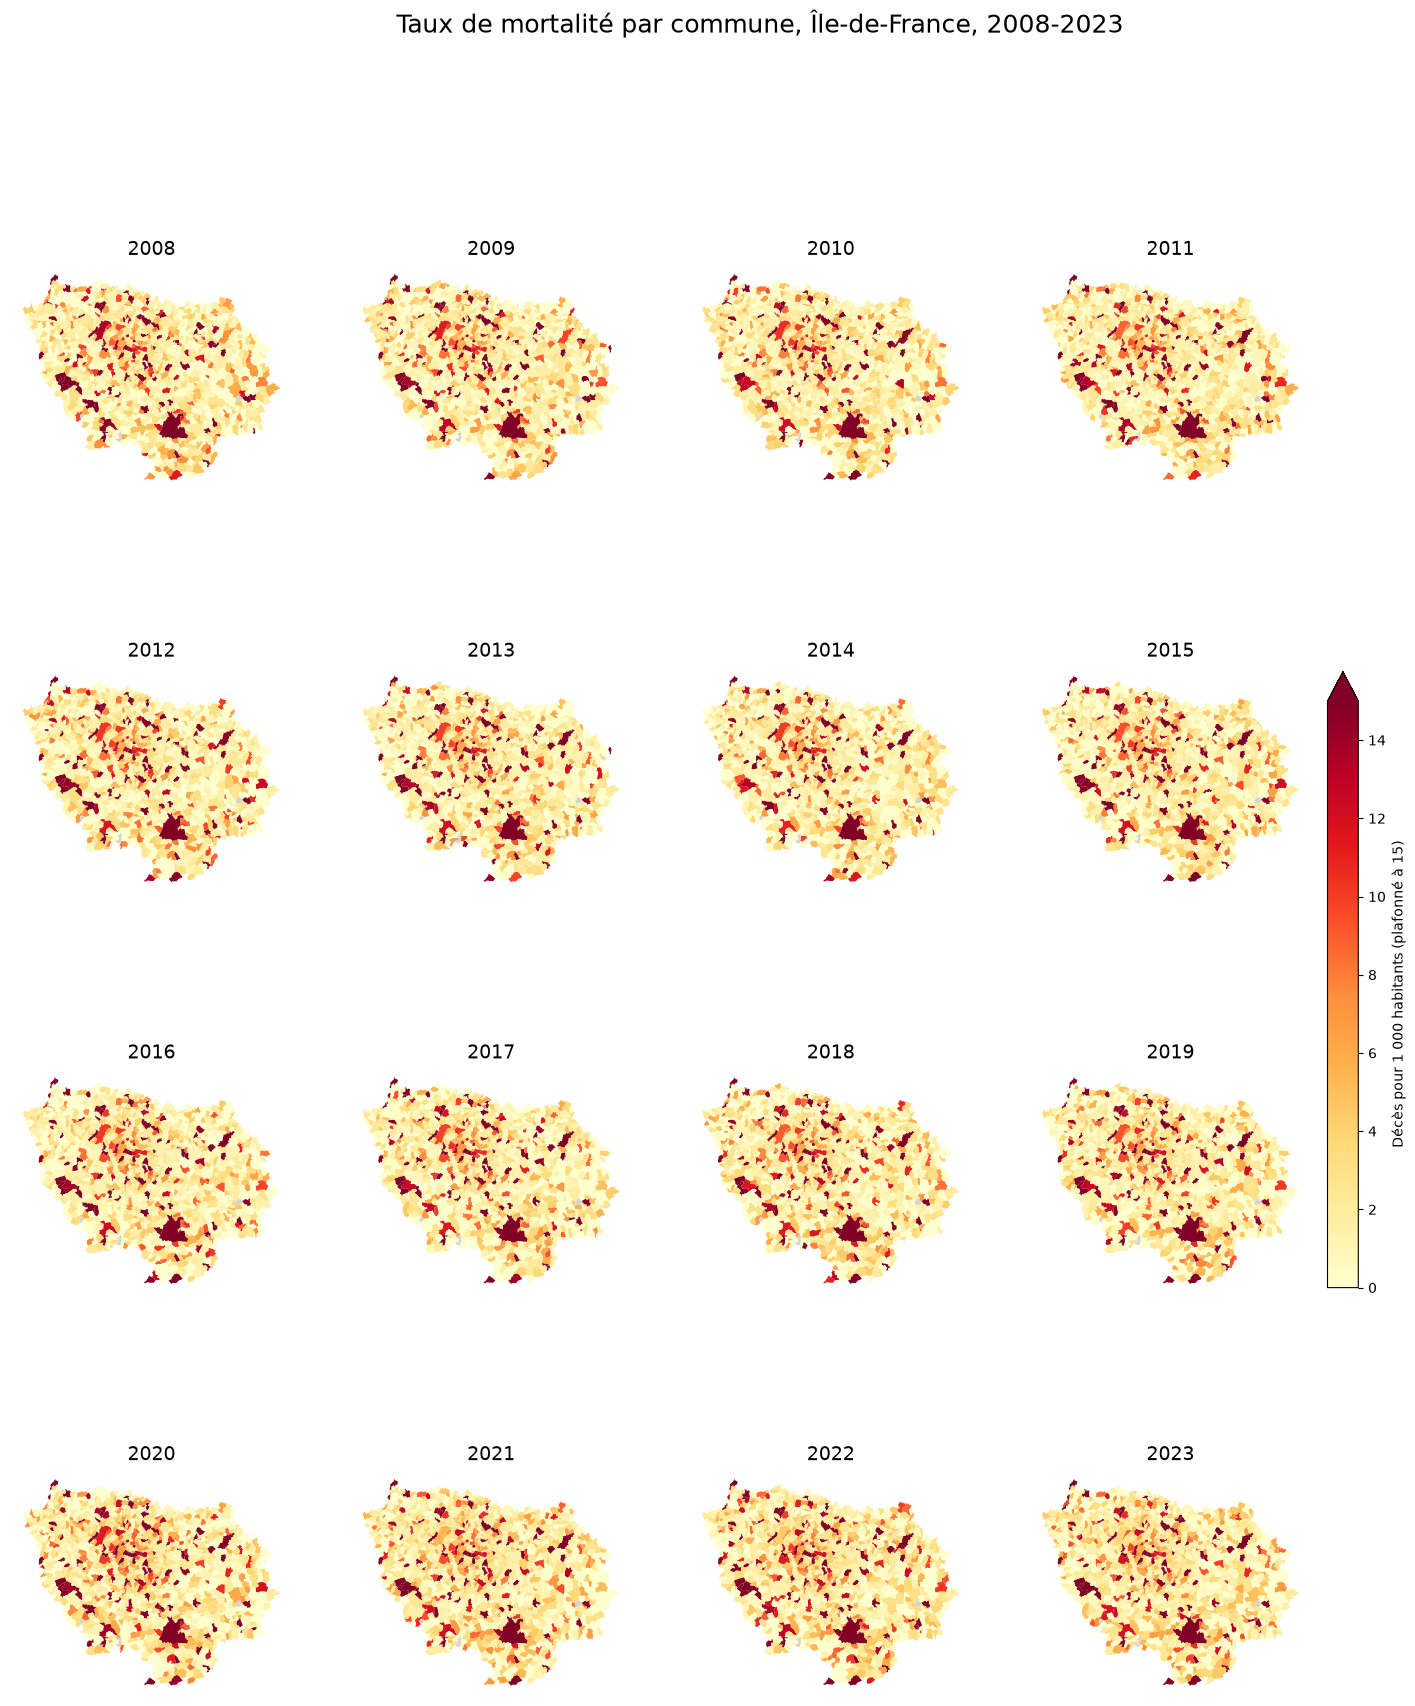

In [ ]:
t = taux.set_index("code_commune")
t[[f"taux_{a}" for a in annees_pop]] = (
    t[[f"taux_{a}" for a in annees_pop]].replace([np.inf, -np.inf], np.nan)
)

print("Contours sans données :", sorted(set(communes["code"]) - set(t.index)))

cap = 15                                   # taux régional env de 6 ; au-delà de 15, rouge foncé
norm = Normalize(vmin=0, vmax=cap)
cmap = "YlOrRd"

def carte(a):
    return communes.merge(t[f"taux_{a}"].rename("taux"),
                          left_on="code", right_index=True, how="left")

fig, axes = plt.subplots(4, 4, figsize=(20, 20))
for ax, a in zip(axes.flat, annees_pop):
    carte(a).plot(column="taux", cmap=cmap, norm=norm, ax=ax,
                  missing_kwds={"color": "lightgrey"})
    ax.set_title(str(a), fontsize=14)
    ax.set_axis_off()

cbar = fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), ax=axes,
                    shrink=0.4, location="right", pad=0.01, extend="max")
cbar.set_label("Décès pour 1 000 habitants (plafonné à 15)")
fig.suptitle("Taux de mortalité par commune, Île-de-France, 2008-2023", fontsize=18)
plt.show()

### c. Prix de l'immobilier 

Comme annoncé lors de la récupération des données, le dataset n'est vraiment pas exhaustif sur l'intégralité des communes. On va quantifier ce manque d'exhaustivité. 

In [38]:
Prix_immo[Prix_immo['region']=='Île-de-France'].describe()

,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
count,530.000000,530.000000,531.000000,534.000000,541.000000,542.000000,547.000000,573.000000,573.000000,573.000000,573.000000,573.000000
mean,3136.758491,3092.501887,3116.832392,3192.464419,3270.308688,3397.588561,3568.210238,4049.050611,4188.766143,4060.462478,3845.490401,3849.719023
std,920.676160,929.669316,933.035648,1014.615461,1064.313541,1172.890040,1285.747144,1950.271711,1911.204726,1843.102954,1728.555377,1743.841473
min,1417.000000,1487.000000,1435.000000,1373.000000,1376.000000,1353.000000,1362.000000,1572.000000,1824.000000,1625.000000,1567.000000,1546.000000
25%,2583.250000,2557.750000,2593.000000,2608.250000,2684.000000,2753.250000,2890.500000,3061.000000,3210.000000,3133.000000,2985.000000,2978.000000
50%,2909.000000,2854.500000,2896.000000,2938.000000,3037.000000,3086.500000,3245.000000,3468.000000,3611.000000,3533.000000,3352.000000,3318.000000
75%,3391.500000,3315.250000,3365.000000,3453.250000,3528.000000,3616.750000,3824.000000,4186.000000,4386.000000,4235.000000,3983.000000,3953.000000
max,8621.000000,8500.000000,7673.000000,9283.000000,9915.000000,10636.000000,11275.000000,14947.000000,15129.000000,15000.000000,14616.000000,14286.000000


In [41]:
Prix_immo[2014].isna().sum()
Prix_immo[2023].isna().sum()

np.int64(7)

## Liens entre nos indices 

### a. Pollution et mortalité 

### b. Pollution et prix de l'immobilier 

## Conclusion